---
title: "Issued 1 June 2023: a seven-model seasonal ensemble"
subtitle: "Every model calibrated with CCA and PCR, combined with construct_mme, and turned into a flexible forecast"
description: "Seven seasonal models started on 1 June 2023, each calibrated against CHIRPS v3.0 at 0.05 degree for July-September to December-February, combined into a multi-model ensemble: skill of every member and of the ensemble, EOF and CCA patterns, calibrated forecasts, and probability of exceedance."
---

## 1. The question and the models

One issue date, **1 June 2023**, and the next six overlapping three-month seasons,
July-September (lead 1) to December-February (lead 6). Every model that can answer
this is calibrated the same way and the calibrated forecasts are averaged, as
[chapter 6](../learn/06-multi-model-ensemble.ipynb) did for one season.

The date was chosen by measurement. A scan of all twelve start months and six leads
(`research/scripts/skill_calendar_scan.py`, at 0.25°) showed that skill follows the
target season: targets from June to December are predictable from any of these leads,
targets from December to July hardly at all. A 1 June start puts four predictable
seasons at leads 1 to 4 and then runs into the wet season at leads 5 and 6.

Which models can answer it was measured before any skill was computed, by
`research/scripts/check_lead_mme_availability.py`. For every candidate and target it
downloads the data with PyCPT's own `download_data` and records four things: the
download worked, every training year holds data, the 2023 forecast holds data, and
the returned target months are the ones requested.

In [1]:
from pathlib import Path
import contextlib
import datetime as dt
import gzip
import io
import json
import re
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapefile
import shapely
from shapely.geometry import shape
import xarray as xr
import cartopy.io.shapereader as shapereader
from scipy.stats import norm, t as student_t
import cptdl as dl
import pycpt
from pycpt import notebook as pycpt_notebook

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research" / "scripts"))
from pycpt_tutorial.country_grid import training_complete_mask
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import seasonal_mme_fits
figures.use_style()
warnings.filterwarnings("ignore", message="All-NaN slice encountered")

predictand_name = "CHIRPS3.PRCP"
issue = dt.datetime(2023, 6, 1)
leads = [1, 2, 3, 4, 5, 6]                 # months from the issue date to the first day of the target
target_length = 3
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
targets = {lead: f"{MONTHS[(issue.month - 1 + lead) % 12]}-{MONTHS[(issue.month - 2 + lead + target_length) % 12]}"
           for lead in leads}
predictor_extent = {"west": 85, "east": 155, "south": -20, "north": 20}
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
training_years = list(range(1992, 2021))   # target years
cpt_args = {
    "transform_predictand": None, "tailoring": None,
    "cca_modes": (2, 2), "x_eof_modes": (3, 3), "y_eof_modes": (3, 3),
    "validation": "crossvalidation", "drymask_threshold": None, "skillmask_threshold": None,
    "crossvalidation_window": 5, "synchronous_predictors": True,
}
case_root = Path.home() / "PyCPT" / "indonesia-issued-2023-06-seasons-mme"
data_dir = repo / "docs/data/seasonal-mme-2023"
assets = repo / "docs/assets/seasonal-mme-2023"
short = lambda name: name.split(".")[0]

audit = {r["model"]: r for r in json.loads((data_dir / "availability.json").read_text())}
allowed_gap = set()                         # every training target year, 1992-2020, must hold data
members, rows = {lead: [] for lead in leads}, []
for model, record in audit.items():
    row = {"model": short(model), "Data Library source": dl.hindcasts[model].split("SOURCES/")[1].split("/.prec")[0].split("/.prcp")[0]}
    for t in record["targets"]:
        if t["case"] != "seasons":
            continue
        gaps = set(t.get("missing_training_years") or [])
        ok = bool(t.get("downloaded") and t.get("forecast_present") and t.get("target_matches") and gaps <= allowed_gap)
        why = "ok" if ok else ("no such lead" if not t.get("downloaded") else
                              "no 2023 forecast" if not t.get("forecast_present") else f"missing {sorted(gaps - allowed_gap)}")
        row[targets[t["lead"]]] = why
        if ok:
            members[t["lead"]].append(model)
    rows.append(row)
order = ["CFSv2.PRCP", "GEOSS2S.PRCP", "CanSIPSIC3.PRCP", "CCSM4.PRCP", "CESM1.PRCP", "SPEAR.PRCP", "SEAS51c.PRCP"]
members = {lead: [m for m in order if m in names] for lead, names in members.items()}
assert all(set(names) <= set(order) for names in members.values())
print("Checked:", sorted({r["checked"][:10] for r in audit.values()}), "| rule: training target years 1992-2020, forecast present, requested months returned")
for lead in leads:
    print(f"Lead {lead} ({targets[lead]}): {len(members[lead])} members:", ", ".join(short(m) for m in members[lead]))
pd.DataFrame(rows).set_index("model")

Checked: ['2026-11-16'] | rule: training target years 1992-2020, forecast present, requested months returned
Lead 1 (Jul-Sep): 7 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR, SEAS51c
Lead 2 (Aug-Oct): 7 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR, SEAS51c
Lead 3 (Sep-Nov): 7 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR, SEAS51c
Lead 4 (Oct-Dec): 6 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR
Lead 5 (Nov-Jan): 6 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR
Lead 6 (Dec-Feb): 6 members: CFSv2, GEOSS2S, CanSIPSIC3, CCSM4, CESM1, SPEAR


,Data Library source,Jul-Sep,Aug-Oct,Sep-Nov,Oct-Dec,Nov-Jan,Dec-Feb
model,,,,,,,
CCSM4,.Models/.NMME/.COLA-RSMAS-CCSM4/.MONTHLY,ok,ok,ok,ok,ok,ok
CESM1,.Models/.NMME/.COLA-RSMAS-CESM1/.MONTHLY,ok,ok,ok,ok,ok,ok
CFSv2,.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SA...,ok,ok,ok,ok,ok,ok
CanSIPSIC3,.Models/.NMME/.CanSIPS-IC3/.HINDCAST/.MONTHLY,ok,ok,ok,ok,ok,ok
CanSIPSIC4,.Models/.NMME/.CanSIPS-IC4/.HINDCAST/.MONTHLY,no 2023 forecast,no 2023 forecast,no 2023 forecast,no 2023 forecast,no 2023 forecast,no 2023 forecast
GCFS2p1,.EU/.Copernicus/.CDS/.C3S/.DWD/.GCFS2p1/.hindcast,"missing [1992, 2020]","missing [1992, 2020]","missing [1992, 2020]",no such lead,no such lead,no such lead
GEOSS2S,.Models/.NMME/.NASA-GEOSS2S/.HINDCAST/.MONTHLY,ok,ok,ok,ok,ok,ok
METEOFRANCE9,.EU/.Copernicus/.CDS/.C3S/.Meteo_France/.Syste...,no 2023 forecast,no 2023 forecast,no 2023 forecast,no such lead,no such lead,no such lead
SEAS51c,.EU/.Copernicus/.CDS/.C3S/.ECMWF/.SEAS51_iri2/...,ok,ok,ok,no such lead,no such lead,no such lead


Six models answer every lead. **SEAS51c** (ECMWF SEAS5 through Copernicus) forecasts
six months, so from 1 June it reaches November: it joins the first three seasons and
not the last three. Training uses target years 1992-2020 (29 years) for every model,
so all members share one sample. These are the years of the skill calendar scan; an
earlier check for a 1 November start found that SPEAR cannot supply target year 1991
there. The other candidates lack training years or a 2023 forecast.

The ensemble therefore has seven members at leads 1 to 3 and six at leads 4 to 6.

## 2. Observations: CHIRPS v3.0 from dekads, native 0.05°

The predictand is built exactly as in the single-model case: for each training target,
the first and last day are read from the hindcast file and the dekads covering those
days are summed, refusing to add them unless they run contiguously.

A 0.05° pixel is kept if **any part of it touches Indonesia** and it has data in all
29 training years of all six targets. "Indonesia" is the 38-province boundary supplied
for this tutorial (credited to Badan Informasi Geospasial, 2022 province dataset), read
unsimplified: it has about 19,000 separate polygons, so small islands count.

Indonesia is a country of coasts and small islands. A rule that keeps only pixels whose
centre is on land drops coastal pixels and whole islands, and a coarse outline drops
islands it does not draw; the cell below counts both effects. Coastal pixels are partly
sea: CHIRPS v3.0 provides values there, and each pixel counts as one whole pixel in the
area-weighted means.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
bounds = pd.DatetimeIndex(source.time_bnds.values.ravel()).values.reshape(-1, 2)
dekad_first, dekad_end = pd.DatetimeIndex(bounds[:, 0]), pd.DatetimeIndex(bounds[:, 1])
box = predictand_extent
region = source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))


def period_total(first, last):
    # Sum of the dekads covering first..last (inclusive days), checked against the stored bounds.
    end = pd.Timestamp(last) + pd.Timedelta(days=1)
    index = np.flatnonzero((dekad_first >= pd.Timestamp(first)) & (dekad_end <= end))
    assert len(index) > 0 and dekad_first[index[0]] == pd.Timestamp(first) and dekad_end[index[-1]] == end, (first, last)
    assert (dekad_first[index[1:]] == dekad_end[index[:-1]]).all(), (first, last)
    return region.isel(time=index).sum("time", skipna=False)


province_file = Path("/mnt/f/temp/hybrid-bias-correction/data/subset/bnd/idn_bnd_adm1")
reader = shapefile.Reader(str(province_file), encoding="utf-8")
provinces = [(sr.record.as_dict()["a1name"], shape(sr.shape.__geo_interface__)) for sr in reader.iterShapeRecords()]
reader.close()
assert len(provinces) == 38 and all(g.is_valid for _, g in provinces)
lon2d, lat2d = np.meshgrid(region.lon, region.lat)
step = float(np.diff(region.lon.values.astype(float)).mean())
pixel_boxes = shapely.box(lon2d - step / 2, lat2d - step / 2, lon2d + step / 2, lat2d + step / 2)
pixel_tree = shapely.STRtree(pixel_boxes.ravel())
touching = np.zeros(pixel_boxes.size, dtype=bool)                     # any overlap with any province
centre_inside = np.zeros(pixel_boxes.size, dtype=bool)                # the rule of the earlier cases
for _, geometry in provinces:
    touching[pixel_tree.query(geometry, predicate="intersects")] = True
    shapely.prepare(geometry)
    centre_inside |= shapely.contains_xy(geometry, lon2d.ravel(), lat2d.ravel())
touching, centre_inside = touching.reshape(lon2d.shape), centre_inside.reshape(lon2d.shape)
country = xr.DataArray(touching, dims=("lat", "lon"), coords={"lat": region.lat, "lon": region.lon})
islands = [part for _, geometry in provinces for part in getattr(geometry, "geoms", [geometry])]

# The outline used by the earlier cases, for comparison only
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
natural_earth = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
natural_earth_touching = np.zeros(pixel_boxes.size, dtype=bool)
natural_earth_touching[pixel_tree.query(natural_earth, predicate="intersects")] = True
natural_earth_touching = natural_earth_touching.reshape(lon2d.shape)


def islands_reached(mask):
    # Island polygons of the boundary with at least one kept pixel overlapping them.
    kept = shapely.STRtree(pixel_boxes[mask])
    return sum(len(kept.query(island, predicate="intersects")) > 0 for island in islands)


def on_model_grid(native):
    pixels = native.where(country).rename({"lat": "Y", "lon": "X"})
    pixels = pixels.assign_coords(Y=np.round(pixels["Y"].values.astype(float), 3), X=np.round(pixels["X"].values.astype(float), 3))
    return pixels.sortby("Y", ascending=False).astype("float32")


def observed_cells(data):
    # Target totals at the native pixels touching Indonesia, on the T, Ti, Tf axis of a PyCPT file.
    native = xr.concat([period_total(a, b) for a, b in zip(data["Ti"].values, data["Tf"].values)],
                       dim=pd.Index(data["T"].values, name="T")).load()
    return on_model_grid(native).assign_coords(Ti=("T", data["Ti"].values), Tf=("T", data["Tf"].values))


def question(lead):
    return dict(fdate=issue, target=targets[lead], target_first_year=training_years[0], target_final_year=training_years[-1],
                predictor_extent=predictor_extent, predictand_extent=predictand_extent)


start = time.monotonic()
prepared = {}
for lead in leads:
    with contextlib.redirect_stdout(io.StringIO()):                 # PyCPT's folder and download messages
        domain_dir = pycpt.setup(case_root / f"lead-{lead}", predictor_extent)
        axis = pycpt_notebook.download_hindcasts(["CFSv2.PRCP"], domain_dir, False, question(lead))[0]
    assert (pd.DatetimeIndex(axis["T"].values).year == np.array(training_years)).all()
    Yl = observed_cells(axis)
    prepared[lead] = dict(domain_dir=domain_dir, Y_all=Yl, complete=training_complete_mask(Yl, training_years))
cells = xr.concat([p["complete"] for p in prepared.values()], "q").all("q")
used = cells.sortby("Y").values                                      # back to the archive's south-to-north order
print(f"Boundary: {len(provinces)} provinces, {len(islands):,} polygons (Natural Earth 1:10m draws {len(natural_earth.geoms)} for Indonesia)")
print(f"Pixels touching Indonesia: {int(touching.sum()):,}; with data in all 29 training years of every target: {int(cells.sum()):,}")
print(f"Of the pixels used here, {int((used & ~natural_earth_touching).sum()):,} touch no Natural Earth polygon (islands and coast it does not draw)")
print(f"Pixels whose centre is inside Indonesia: {int(centre_inside.sum()):,}; of the pixels used here, {int((used & ~centre_inside).sum()):,} are coastal pixels that rule would drop")
print(f"Island polygons in the boundary: {len(islands)}; reached by the pixels used here: {islands_reached(used)}; reached by centre-inside pixels with data: {islands_reached(used & centre_inside)}")

local_files = {}
for lead, p in prepared.items():
    Yl = p["Y_all"].where(cells).transpose("T", "Y", "X").rename("precipitation")
    Yl.attrs = {"units": "mm", "missing": -999.0,
                "long_name": f"CHIRPS v3.0 {targets[lead]} rainfall total, Indonesia land, native 0.05 degree"}
    path = case_root / f"lead-{lead}" / f"local-CHIRPS3-{targets[lead]}-1992-2020.nc"
    same = False
    if path.exists():
        with xr.open_dataset(path) as old:
            same = bool(old.precipitation.shape == Yl.shape and np.array_equal(old.precipitation.values, Yl.values, equal_nan=True)
                        and (old["T"].values == Yl["T"].values).all())
    if not same:                             # an unchanged file is left alone, so finished fits stay valid
        save_netcdf(Yl.to_dataset(), path, overwrite=True,
                    metadata={"source_file": chirps3_file.name,
                              "aggregation": "sum of the dekads tiling each target; native 0.05 degree pixels that touch Indonesia (any overlap)",
                              "boundary": "Supplied 38-province boundary (idn_bnd_adm1, credited to Badan Informasi Geospasial, 2022), unsimplified; pixels with any overlap", "training_years": "target years 1992-2020"})
    local_files[lead] = path
    p["Yl"] = Yl
    print(f"Lead {lead} {targets[lead]}: {pd.Timestamp(Yl['Ti'].values[0]):%d %b %Y} ... {pd.Timestamp(Yl['Tf'].values[-1]):%d %b %Y}, "
          f"predictand file {'unchanged' if same else 'written'}")
print(f"Observations ready in {time.monotonic() - start:.0f} s")

Boundary: 38 provinces, 19,275 polygons (Natural Earth 1:10m draws 264 for Indonesia)
Pixels touching Indonesia: 70,215; with data in all 29 training years of every target: 69,640
Of the pixels used here, 3,010 touch no Natural Earth polygon (islands and coast it does not draw)
Pixels whose centre is inside Indonesia: 61,572; of the pixels used here, 8,078 are coastal pixels that rule would drop


Island polygons in the boundary: 19275; reached by the pixels used here: 18187; reached by centre-inside pixels with data: 6518


Lead 1 Jul-Sep: 01 Jul 1992 ... 30 Sep 2020, predictand file unchanged


Lead 2 Aug-Oct: 01 Aug 1992 ... 31 Oct 2020, predictand file unchanged


Lead 3 Sep-Nov: 01 Sep 1992 ... 30 Nov 2020, predictand file unchanged


Lead 4 Oct-Dec: 01 Oct 1992 ... 31 Dec 2020, predictand file unchanged


Lead 5 Nov-Jan: 01 Nov 1992 ... 31 Jan 2021, predictand file unchanged


Lead 6 Dec-Feb: 01 Dec 1991 ... 29 Feb 2020, predictand file unchanged
Observations ready in 74 s


## 3. Calibrate every model, both ways

Each of the 78 fits (six leads, seven or six models, CCA and PCR) is one call of
PyCPT's `evaluate_models`, with the settings of the single-model case: 3 predictor and
3 predictand EOFs, 2 CCA modes, cross-validation window 5. At 0.05° one fit takes many
minutes, most of it writing and reading CPT's files for some 67,000 pixels, so
`research/scripts/seasonal_mme_fits.py` runs them side by side, one process each, and
keeps a compact result per fit: the cross-validated deterministic hindcasts, the
forecast, the skill maps and the EOF and CCA patterns. Before fitting, each job checks
again that the model's files hold every training year, the forecast, and the requested
target months.

A finished fit is reused when its settings, model data and observations are unchanged,
so re-running this notebook does not refit.

After the fits the same script builds the ensemble for each lead with PyCPT's
`construct_mme`, once from the CCA members and once from the PCR members.

In [3]:
config = {"case_root": str(case_root), "issue": issue.date().isoformat(), "training": [training_years[0], training_years[-1]],
          "predictor_extent": predictor_extent, "predictand_extent": predictand_extent,
          "cpt_args": {k: list(v) if isinstance(v, tuple) else v for k, v in cpt_args.items()},
          "leads": {str(lead): {"target": targets[lead], "local_file": str(local_files[lead]), "models": members[lead]} for lead in leads}}
start = time.monotonic()
fit_records = seasonal_mme_fits.run(config, workers=39, log=lambda line: None)
failed = [r for r in fit_records if r["status"] == "failed"]
assert not failed, failed[:3]
fits = pd.DataFrame([r for r in fit_records if "model" in r])
print(f"{len(fits)} fits: {dict(fits['status'].value_counts())}; this run took {(time.monotonic() - start) / 60:.1f} min")
print(f"Minutes per fit when fitted: median {fits['seconds'].median() / 60:.1f}, range {fits['seconds'].min() / 60:.1f} to {fits['seconds'].max() / 60:.1f}")
fits.assign(minutes=(fits["seconds"] / 60).round(1), model=fits["model"].map(short)).pivot_table(
    index=["model", "method"], columns="lead", values="minutes").reindex([short(m) for m in order], level=0)

Input data will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/data

Figures will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/figures

Input data will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/data

Input data will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/data

Input data will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/data

Input data will be saved in ~/PyCPT/indonesia-issued-2023-06-seasons-mme/lead-1/85W-155E_to_-20S-20N/data

... (1,307 outputs left out)

Reusing already-downloaded CFSv2.PRCP

Reusing already-downloaded CFSv2.PRCP

78 fits: {'reused': np.int64(77), 'fitted': np.int64(1)}; this run took 17.6 min
Minutes per fit when fitted: median 32.8, range 11.1 to 40.4


lead                  1     2     3     4     5     6
model      method                                    
CFSv2      CCA     36.8  37.2  37.2  14.8  30.7  29.8
           PCR     35.6  34.9  36.2  37.6  26.8  26.7
GEOSS2S    CCA     15.1  40.1  40.4  37.8  27.9  29.7
           PCR     36.4  36.7  37.6  37.2  26.2  26.4
CanSIPSIC3 CCA     38.1  36.9  35.5  39.6  30.0  29.2
           PCR     36.2  35.3  36.3  27.1  11.1  29.1
CCSM4      CCA     35.4  38.2  39.8  28.3  29.9  28.9
           PCR     37.0  36.8  37.7  27.3  26.8  27.0
CESM1      CCA     39.0  15.5  15.1  26.7  29.7  15.1
           PCR     37.4  37.6  36.4  25.7  29.7  27.0
SPEAR      CCA     37.6  15.0  38.0  27.1  29.5  28.3
           PCR     14.5  36.5  36.2  27.1  29.6  26.9
SEAS51c    CCA     15.0  14.9  39.5   NaN   NaN   NaN
           PCR     37.7  36.0  37.1   NaN   NaN   NaN

## 4. Load the results at the Indonesian pixels

Everything below works on plain arrays with one value per kept pixel, in a fixed
pixel order (north to south, west to east). Two checks come first, because the rest
depends on them: the ensemble is the plain average of its members, and CPT's own
Pearson map equals the correlation recomputed from the cross-validated hindcasts.

In [4]:
grid_mask = cells.transpose("Y", "X")
grid_Y, grid_X = grid_mask["Y"], grid_mask["X"]
flat = np.flatnonzero(grid_mask.values.ravel())
n = len(flat)
pixel_lat = np.repeat(grid_Y.values, grid_mask.sizes["X"])[flat]
pixel_lon = np.tile(grid_X.values, grid_mask.sizes["Y"])[flat]
weight = np.cos(np.deg2rad(pixel_lat))


def pix(a):
    # A (..., Y, X) DataArray on the predictand grid -> (..., pixel) array.
    a = a.reindex(Y=grid_Y, X=grid_X, method="nearest", tolerance=1e-3).transpose(..., "Y", "X")
    return a.values.reshape(a.shape[:-2] + (-1,))[..., flat].astype("float64")


def field(values):
    # (pixel,) array -> (Y, X) DataArray for mapping.
    full = np.full(grid_mask.size, np.nan)
    full[flat] = values
    return xr.DataArray(full.reshape(grid_mask.shape), coords={"Y": grid_Y, "X": grid_X}, dims=("Y", "X"))


def area_mean(values):
    ok = np.isfinite(values)
    return float((values[ok] * weight[ok]).sum() / weight[ok].sum())


def corr(a, b):
    a, b = a - a.mean(0), b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a * a).sum(0) * (b * b).sum(0))


def compact(lead, name, method):
    return prepared[lead]["domain_dir"] / "compact" / f"{name}_{method}.nc"


start = time.monotonic()
obs = {lead: pix(prepared[lead]["Yl"]) for lead in leads}             # (29, pixel)
names = {lead: members[lead] + ["MME"] for lead in leads}
res, patterns = {}, {}
for lead in leads:
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            with xr.open_dataset(compact(lead, name, method)) as ds:
                res[lead, name, method] = dict(
                    h=pix(ds.cv_hindcast), f=pix(ds.forecast), p=pix(ds.forecast_probability), pev=pix(ds.forecast_pev),
                    pearson=pix(ds.skill_pearson), afc=pix(ds.skill_two_alternative_forced_choice), attrs=dict(ds.attrs))
                if name == "MME":
                    res[lead, name, method]["members_mean"] = pix(ds.members_mean_forecast)
                    if method == "CCA":
                        res[lead, name, method]["flex"] = {k[5:]: pix(ds[k]) for k in ds.data_vars if k.startswith("flex_")}
                elif method == "CCA":
                    patterns[lead, name] = ds[[v for v in ds.data_vars if v[:2] in ("x_", "y_")]].load()
print(f"Loaded {len(res)} results in {time.monotonic() - start:.0f} s")

gaps = {"MME forecast minus mean of members (mm)": 0.0, "MME hindcasts minus mean of members (mm)": 0.0,
        "CPT Pearson minus recomputed, MME": 0.0, "CPT Pearson minus recomputed, members": 0.0}
for lead in leads:
    for method in ("CCA", "PCR"):
        mme = res[lead, "MME", method]
        mean_h = np.mean([res[lead, m, method]["h"] for m in members[lead]], axis=0)
        gaps["MME forecast minus mean of members (mm)"] = max(gaps["MME forecast minus mean of members (mm)"], float(np.nanmax(abs(mme["f"] - mme["members_mean"]))))
        gaps["MME hindcasts minus mean of members (mm)"] = max(gaps["MME hindcasts minus mean of members (mm)"], float(np.nanmax(abs(mme["h"] - mean_h))))
        gaps["CPT Pearson minus recomputed, MME"] = max(gaps["CPT Pearson minus recomputed, MME"], float(np.nanmax(abs(mme["pearson"] - corr(mme["h"], obs[lead])))))
        for m in members[lead]:
            gaps["CPT Pearson minus recomputed, members"] = max(gaps["CPT Pearson minus recomputed, members"],
                                                                float(np.nanmax(abs(res[lead, m, method]["pearson"] - corr(res[lead, m, method]["h"], obs[lead])))))
pd.Series(gaps, name="largest absolute difference").to_frame()

Loaded 90 results in 24 s


,largest absolute difference
MME forecast minus mean of members (mm),0.000000
MME hindcasts minus mean of members (mm),0.000279
"CPT Pearson minus recomputed, MME",0.000100
"CPT Pearson minus recomputed, members",0.000016


## 5. Skill of every member and of the ensemble

Four scores, each computed at every pixel and summarised as an area-weighted mean
(weights: cosine of latitude):

- **Pearson correlation** of the cross-validated hindcasts with the observations,
  1992-2020 (CPT's map).
- **2AFC**: the chance that the hindcasts rank two different years in the observed
  order, 50% for no skill (CPT's map).
- **Raw correlation**: the model's own rainfall, interpolated to the pixels, against
  the observations. No fitting is involved, so it needs no cross-validation.
- **Cross-validated RPSS** of tercile probabilities. PyCPT's own probabilistic scores
  are computed from in-sample probabilities (its source says they are
  "unrealistically optimistic"), so they are not used here. Instead, for each
  training year the notebook leaves out that year and its two neighbours on each side
  (the cross-validation window), takes the tercile boundaries (33rd and 67th
  percentiles, Hazen rule) from the remaining observations and the error spread from
  the remaining cross-validated errors, and gives the left-out year a Student's t
  distribution centred on its cross-validated hindcast. The ranked probability score
  of those probabilities is compared with a **climatological forecast put through
  the same steps**: its "hindcast" for a year is the mean of the observations outside
  that year's window, and its spread comes from its own errors in the remaining
  years. Above 0 means the model adds information to climatology. This construction is
  this tutorial's, not CPT's.

In [5]:
def cv_rps(hindcast, observed, window=5):
    # Ranked probability score of leave-window-out tercile probabilities, summed over the years, per pixel.
    T = observed.shape[0]
    error = hindcast - observed
    rps = np.zeros(observed.shape[1])
    half = window // 2
    for i in range(T):
        left_out = [(i + k) % T for k in range(-half, half + 1)]       # CPT's window wraps around the ends
        keep = np.setdiff1d(np.arange(T), left_out)
        lower, upper = np.quantile(observed[keep], [0.33, 0.67], axis=0, method="hazen")
        scale = np.sqrt((error[keep] ** 2).mean(0))
        dof = len(keep) - 1
        below = student_t.cdf((lower - hindcast[i]) / scale, dof)
        not_above = student_t.cdf((upper - hindcast[i]) / scale, dof)
        rps += (below - (observed[i] < lower)) ** 2 + (not_above - (observed[i] <= upper)) ** 2
    return rps


def climatology_hindcast(observed, window=5):
    # The forecast with no model: for each year, the mean of the observations outside its window.
    T, half = observed.shape[0], window // 2
    return np.stack([observed[np.setdiff1d(np.arange(T), [(i + k) % T for k in range(-half, half + 1)])].mean(0) for i in range(T)])


reference_rps = {lead: cv_rps(climatology_hindcast(obs[lead]), obs[lead]) for lead in leads}


def cv_rpss(hindcast, lead):
    return 1 - cv_rps(hindcast, obs[lead]) / reference_rps[lead]


start = time.monotonic()
raw = {}
for lead in leads:
    for m in members[lead]:
        with contextlib.redirect_stdout(io.StringIO()):            # the files are already in the case folder
            _, X, _ = pycpt.download_data(predictand_name, local_files[lead], [m], question(lead), prepared[lead]["domain_dir"], False)
        x = X[0].where(X[0] > -999).interp(Y=grid_Y, X=grid_X, method="linear")
        raw[lead, m] = x.transpose("T", "Y", "X").values.reshape(len(training_years), -1)[:, flat]
    raw[lead, "MME"] = np.mean([raw[lead, m] for m in members[lead]], axis=0)

label = {}
for lead in leads:
    first, last = (pd.Timestamp(v) for v in res[lead, "CFSv2.PRCP", "CCA"]["attrs"]["forecast_target"].split(" to "))
    label[lead] = "".join(MONTHS[(first.month - 1 + k) % 12][0] for k in range(3)) + (
        f" {first.year}-{last.year % 100:02d}" if first.year != last.year else f" {first.year}")

rows = []
for lead in leads:
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            r["rpss"] = cv_rpss(r["h"], lead)
            rows.append({"lead": lead, "target": label[lead], "model": short(name), "method": method,
                         "Pearson": area_mean(r["pearson"]), "2AFC (%)": area_mean(r["afc"]), "CV RPSS": area_mean(r["rpss"])})
        res[lead, name, "raw"] = dict(pearson=corr(raw[lead, name], obs[lead]))
        rows.append({"lead": lead, "target": label[lead], "model": short(name), "method": "raw",
                     "Pearson": area_mean(res[lead, name, "raw"]["pearson"])})
skill_table = pd.DataFrame(rows).set_index(["lead", "model", "method"]).sort_index()
print(f"Scores in {time.monotonic() - start:.0f} s")
# Cross-validation makes a forecast with no model correlate negatively with the observations
# (leaving a wet year out lowers the mean of the rest), so 0 is not the no-skill level of
# a cross-validated correlation. The same no-model forecast is the RPSS reference.
no_model_pearson = {lead: area_mean(corr(climatology_hindcast(obs[lead]), obs[lead])) for lead in leads}
print("Area-weighted mean Pearson of the no-model (climatological) cross-validated hindcast, by lead:",
      {lead: round(v, 3) for lead, v in no_model_pearson.items()})
skill_table["Pearson"].unstack("lead").round(3)

Scores in 278 s


Area-weighted mean Pearson of the no-model (climatological) cross-validated hindcast, by lead: {1: -0.245, 2: -0.291, 3: -0.287, 4: -0.331, 5: -0.382, 6: -0.418}


lead                   1      2      3      4      5      6
model      method                                          
CCSM4      CCA     0.431  0.531  0.544  0.468  0.168  0.087
           PCR     0.433  0.511  0.524  0.441  0.160  0.076
           raw     0.410  0.333  0.125  0.025 -0.063  0.003
CESM1      CCA     0.458  0.515  0.551  0.463  0.225  0.157
           PCR     0.440  0.497  0.533  0.447  0.206  0.148
           raw     0.522  0.481  0.333  0.076 -0.033 -0.044
CFSv2      CCA     0.495  0.595  0.521  0.484  0.242  0.179
           PCR     0.474  0.581  0.506  0.453  0.235  0.159
           raw     0.564  0.589  0.470  0.271  0.052 -0.022
CanSIPSIC3 CCA     0.492  0.563  0.530  0.455  0.236  0.208
           PCR     0.471  0.560  0.511  0.429  0.235  0.210
           raw     0.612  0.630  0.509  0.261  0.044 -0.036
GEOSS2S    CCA     0.565  0.630  0.553  0.460  0.164  0.154
           PCR     0.551  0.633  0.553  0.455  0.186  0.170
           raw     0.579  0.607  0.545  0.449  0.287  0.132
MME        CCA     0.551  0.617  0.576  0.496  0.200  0.168
           PCR     0.536  0.615  0.566  0.483  0.217  0.165
           raw     0.651  0.658  0.565  0.357  0.139  0.064
SEAS51c    CCA     0.509  0.522  0.431    NaN    NaN    NaN
           PCR     0.484  0.519  0.429    NaN    NaN    NaN
           raw     0.636  0.629  0.535    NaN    NaN    NaN
SPEAR      CCA     0.540  0.556  0.454  0.359  0.041  0.120
           PCR     0.509  0.542  0.440  0.336  0.082  0.088
           raw     0.608  0.587  0.520  0.381  0.228  0.131

In [6]:
skill_table["CV RPSS"].dropna().unstack("lead").round(3)

lead                   1      2      3      4      5      6
model      method                                          
CCSM4      CCA     0.173  0.229  0.241  0.187  0.057  0.031
           PCR     0.174  0.211  0.228  0.169  0.038  0.009
CESM1      CCA     0.181  0.215  0.250  0.199  0.077  0.068
           PCR     0.176  0.203  0.240  0.188  0.053  0.044
CFSv2      CCA     0.212  0.309  0.228  0.219  0.099  0.089
           PCR     0.193  0.294  0.221  0.201  0.076  0.061
CanSIPSIC3 CCA     0.235  0.290  0.238  0.206  0.103  0.098
           PCR     0.219  0.283  0.231  0.185  0.079  0.086
GEOSS2S    CCA     0.255  0.342  0.261  0.203  0.079  0.077
           PCR     0.246  0.341  0.265  0.199  0.069  0.076
MME        CCA     0.261  0.320  0.278  0.229  0.102  0.092
           PCR     0.255  0.318  0.276  0.224  0.093  0.085
SEAS51c    CCA     0.220  0.243  0.162    NaN    NaN    NaN
           PCR     0.202  0.244  0.160    NaN    NaN    NaN
SPEAR      CCA     0.240  0.234  0.174  0.138  0.028  0.054
           PCR     0.213  0.218  0.160  0.127  0.016  0.025

The same numbers as a chart: one line per member, the ensemble in black, for CCA and
for PCR. The dashed grey line is the raw multi-model mean, with no calibration.

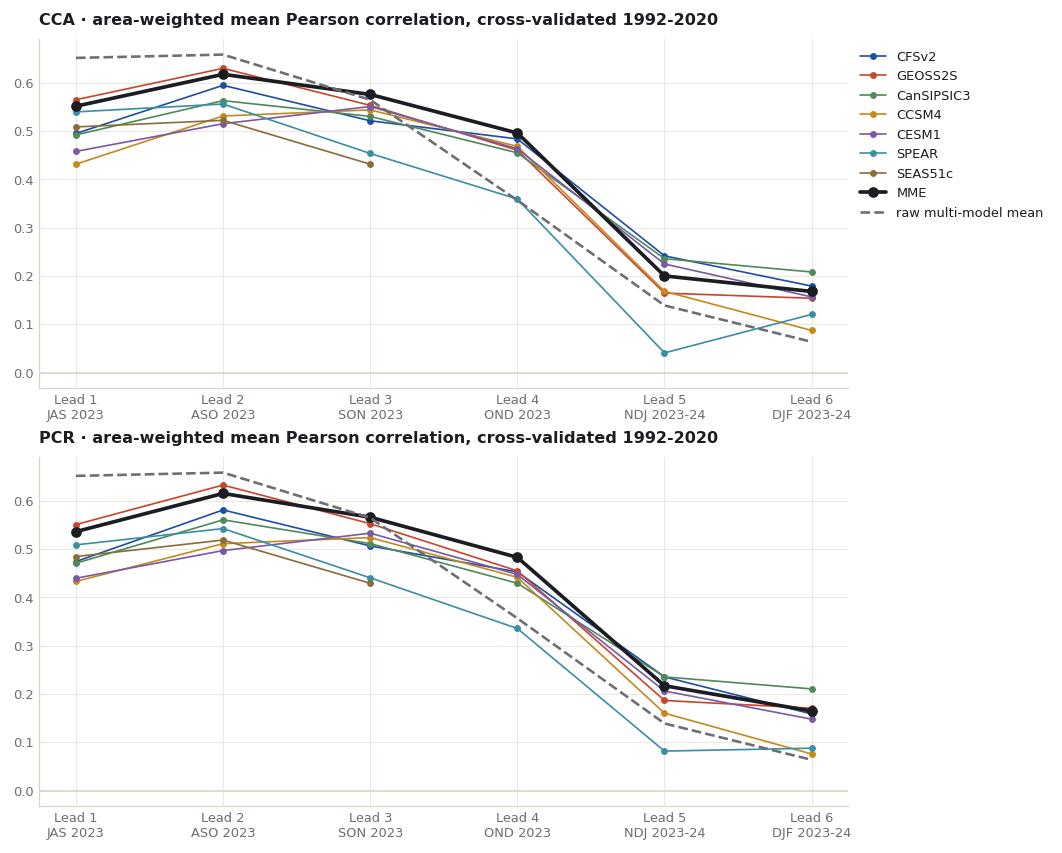

In [7]:
model_colours = dict(zip([short(m) for m in order], figures.CYCLE + ["#8a6d3b"]))
fig, grid = figures.stacked([3.3, 3.3], width=figures.MAP_WIDTH)
for row, method in enumerate(["CCA", "PCR"]):
    ax = fig.add_subplot(grid[row, 0])
    ax.axhline(0, color=figures.LINE, linewidth=1)
    for m in order:
        which = [lead for lead in leads if m in members[lead]]
        ax.plot(which, [skill_table.loc[(lead, short(m), method), "Pearson"] for lead in which], "-o", markersize=3.5,
                linewidth=1.1, color=model_colours[short(m)], label=short(m))
    ax.plot(leads, [skill_table.loc[(lead, "MME", method), "Pearson"] for lead in leads], "-o", color=figures.INK, linewidth=2.4, label="MME")
    ax.plot(leads, [skill_table.loc[(lead, "MME", "raw"), "Pearson"] for lead in leads], "--", color=figures.MUTED, label="raw multi-model mean")
    ax.set_xticks(leads, [f"Lead {lead}\n{label[lead]}" for lead in leads])
    ax.set_title(f"{method} · area-weighted mean Pearson correlation, cross-validated 1992-2020")
    if row == 0:
        ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "pearson-by-lead-models.png")
plt.show()

Did combining help? For each lead: the ensemble against CFSv2 alone and against the
best single member, and the share of pixels where the ensemble's correlation is higher
than CFSv2's.

In [8]:
rows = []
for lead in leads:
    for method in ("CCA", "PCR"):
        member_scores = {short(m): skill_table.loc[(lead, short(m), method), "Pearson"] for m in members[lead]}
        best = max(member_scores, key=member_scores.get)
        mme, cfs = res[lead, "MME", method]["pearson"], res[lead, "CFSv2.PRCP", method]["pearson"]
        rows.append({"lead": lead, "target": label[lead], "method": method, "members": len(members[lead]),
                     "MME Pearson": area_mean(mme), "CFSv2 Pearson": member_scores["CFSv2"],
                     "best member": best, "best member Pearson": member_scores[best],
                     "raw multi-model mean Pearson": skill_table.loc[(lead, "MME", "raw"), "Pearson"],
                     "pixels where MME > CFSv2 (%)": float((weight * (mme > cfs)).sum() / weight.sum() * 100),
                     "MME CV RPSS": skill_table.loc[(lead, "MME", method), "CV RPSS"]})
gain = pd.DataFrame(rows).set_index(["lead", "method"])
gain.round(3)

target  members  MME Pearson  CFSv2 Pearson best member  \
lead method                                                                 
1    CCA        JAS 2023        7        0.551          0.495     GEOSS2S   
     PCR        JAS 2023        7        0.536          0.474     GEOSS2S   
2    CCA        ASO 2023        7        0.617          0.595     GEOSS2S   
     PCR        ASO 2023        7        0.615          0.581     GEOSS2S   
3    CCA        SON 2023        7        0.576          0.521     GEOSS2S   
     PCR        SON 2023        7        0.566          0.506     GEOSS2S   
4    CCA        OND 2023        6        0.496          0.484       CFSv2   
     PCR        OND 2023        6        0.483          0.453     GEOSS2S   
5    CCA     NDJ 2023-24        6        0.200          0.242       CFSv2   
     PCR     NDJ 2023-24        6        0.217          0.235  CanSIPSIC3   
6    CCA     DJF 2023-24        6        0.168          0.179  CanSIPSIC3   
     PCR     DJF 2023-24        6        0.165          0.159  CanSIPSIC3   

             best member Pearson  raw multi-model mean Pearson  \
lead method                                                      
1    CCA                   0.565                         0.651   
     PCR                   0.551                         0.651   
2    CCA                   0.630                         0.658   
     PCR                   0.633                         0.658   
3    CCA                   0.553                         0.565   
     PCR                   0.553                         0.565   
4    CCA                   0.484                         0.357   
     PCR                   0.455                         0.357   
5    CCA                   0.242                         0.139   
     PCR                   0.235                         0.139   
6    CCA                   0.208                         0.064   
     PCR                   0.210                         0.064   

             pixels where MME > CFSv2 (%)  MME CV RPSS  
lead method                                             
1    CCA                           89.643        0.261  
     PCR                           85.597        0.255  
2    CCA                           70.604        0.320  
     PCR                           72.147        0.318  
3    CCA                           87.993        0.278  
     PCR                           84.907        0.276  
4    CCA                           64.879        0.229  
     PCR                           66.592        0.224  
5    CCA                           34.507        0.102  
     PCR                           44.184        0.093  
6    CCA                           44.959        0.092  
     PCR                           51.048        0.085

Where the ensemble's skill sits: the cross-validated correlation of the CCA ensemble
at each lead, in one column.

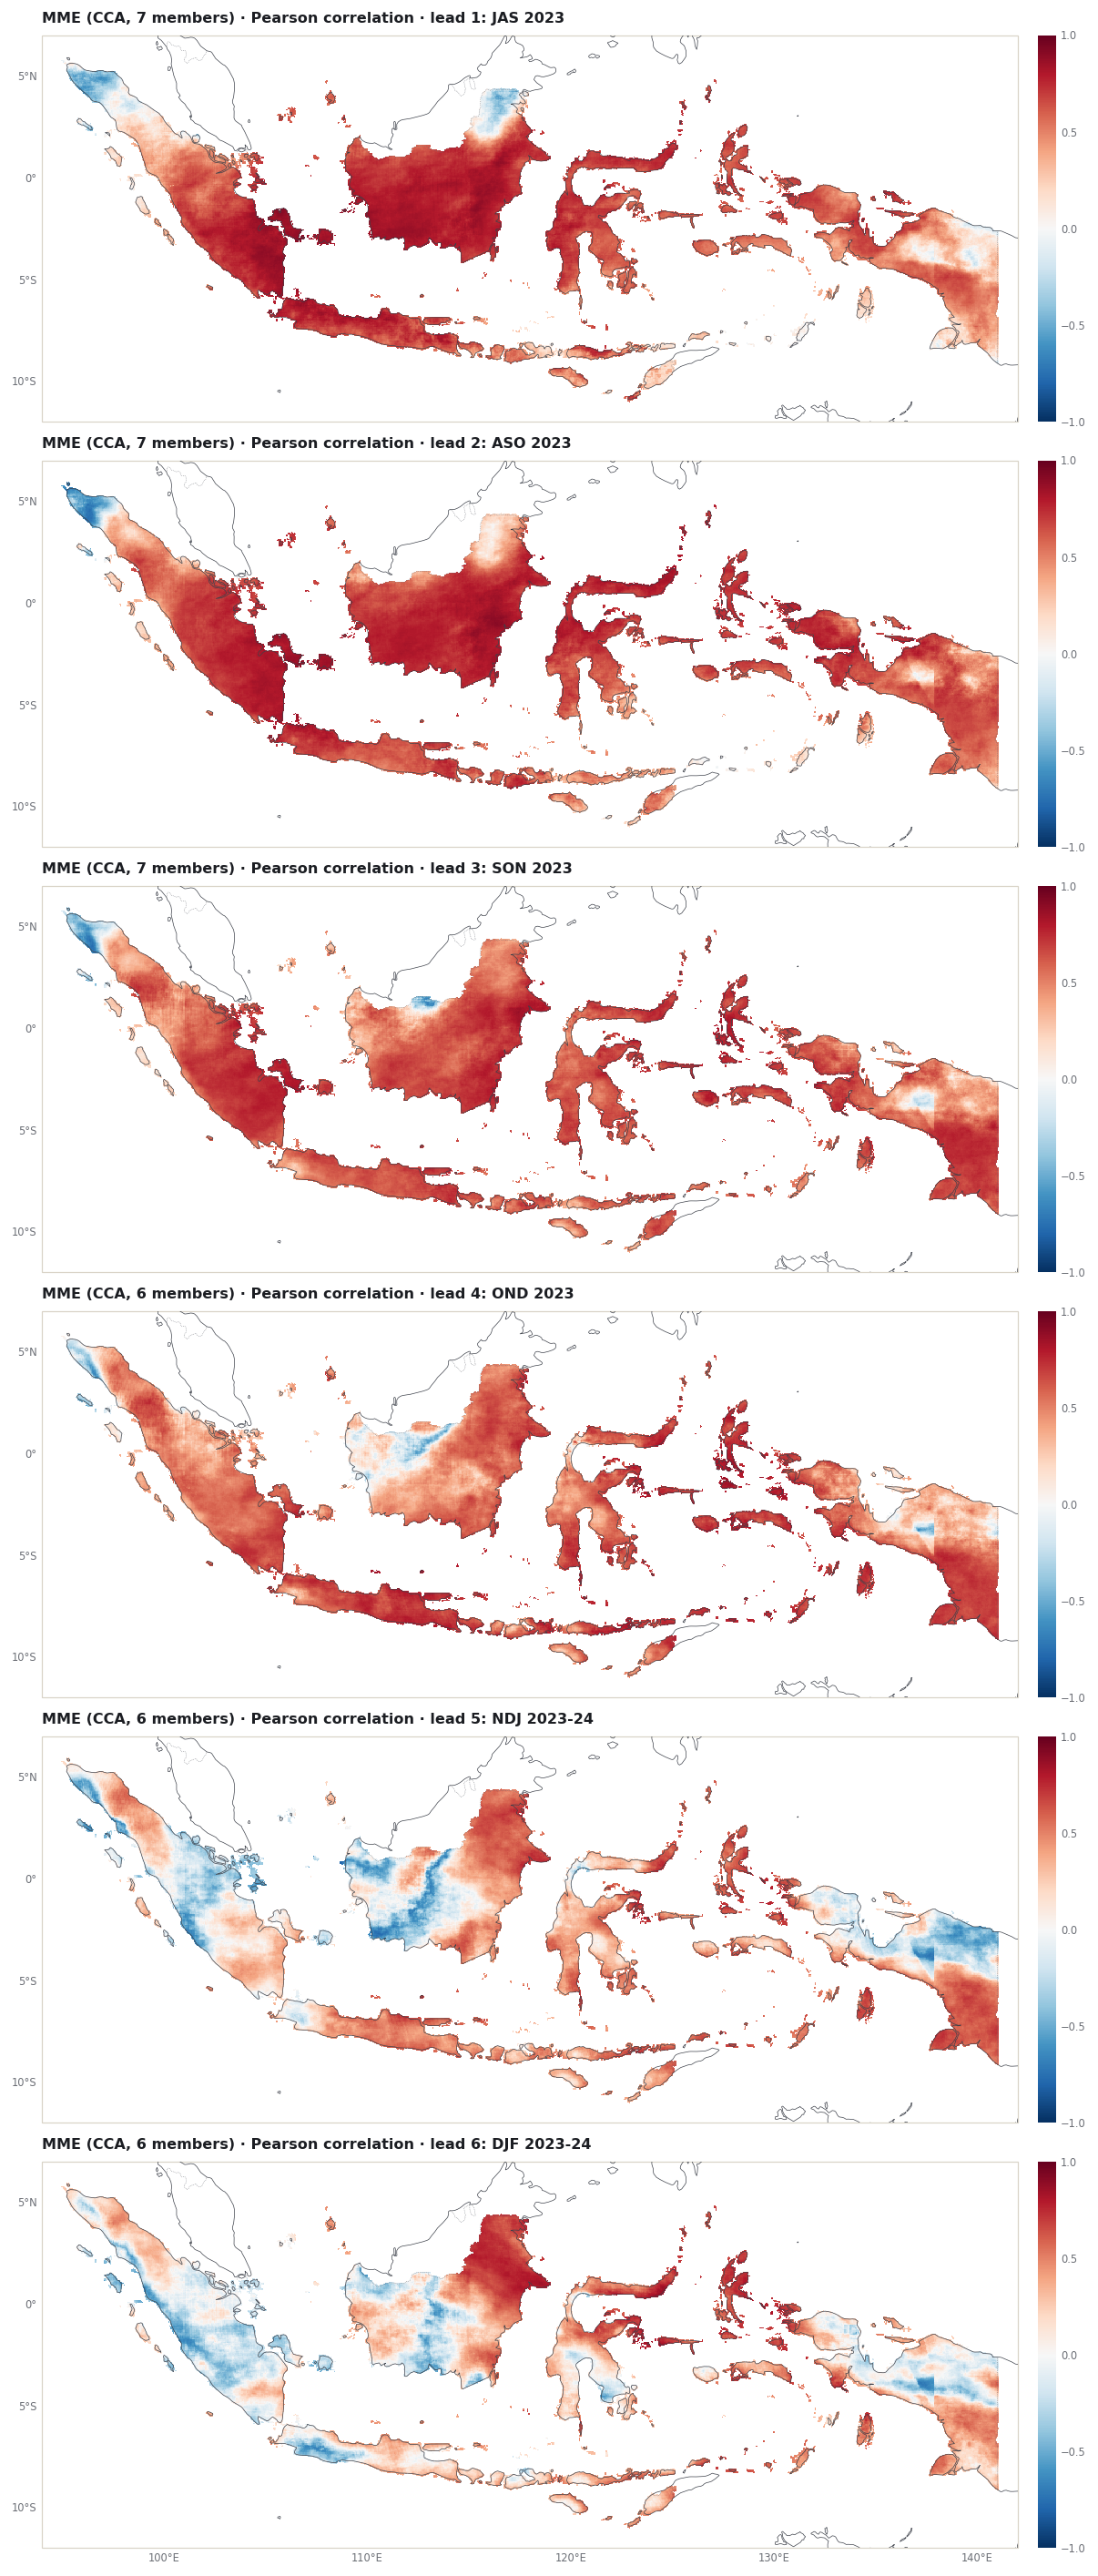

In [9]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, field(res[lead, "MME", "CCA"]["pearson"]), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"MME (CCA, {len(members[lead])} members) · Pearson correlation · lead {lead}: {label[lead]}")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "mme-pearson-by-lead.png")
plt.show()

## 6. EOF patterns and CCA modes

CCA does not relate the two fields point by point. It first reduces each to a few
**EOFs** (patterns that explain the most year-to-year variance, with a score per year),
then finds pairs of combinations of those, the **CCA modes**, whose score series are
as correlated as possible. Looking at them shows what a calibration is actually using.

These patterns come from the fit to all 29 training years, not from the
cross-validation folds, so they describe the fitted model and are not evidence of
skill. CPT's loadings are in its own units; only their sign and shape are read here.
The predictand EOFs depend on the observations alone, so they are the same for every
model at a given lead.

In [10]:
rows = []
for (lead, name), ds in patterns.items():
    row = {"lead": lead, "model": short(name)}
    for mode in (1, 2):
        xs, ys = ds.x_cca_scores.sel(Mode=mode).values, ds.y_cca_scores.sel(Mode=mode).values
        row[f"canonical correlation {mode}"] = float(np.corrcoef(xs, ys)[0, 1])
    for mode in (1, 2, 3):
        row[f"X EOF {mode} (%)"] = float(ds.x_explained_variance.sel(Mode=mode))
    for mode in (1, 2, 3):
        row[f"Y EOF {mode} (%)"] = float(ds.y_explained_variance.sel(Mode=mode))
    rows.append(row)
mode_table = pd.DataFrame(rows).set_index(["lead", "model"]).sort_index()
same_y = max(float(abs(abs(patterns[lead, m].y_eof_loadings) - abs(patterns[lead, "CFSv2.PRCP"].y_eof_loadings)).max())
             for lead in leads for m in members[lead])
print(f"Predictand EOF loadings, largest difference between models at the same lead (sign ignored): {same_y:.2e}")
mode_table.round(2)

Predictand EOF loadings, largest difference between models at the same lead (sign ignored): 0.00e+00


canonical correlation 1  canonical correlation 2  \
lead model                                                          
1    CCSM4                          0.81                     0.57   
     CESM1                          0.80                     0.76   
     CFSv2                          0.84                     0.69   
     CanSIPSIC3                     0.86                     0.65   
     GEOSS2S                        0.91                     0.72   
     SEAS51c                        0.88                     0.68   
     SPEAR                          0.86                     0.71   
2    CCSM4                          0.82                     0.77   
     CESM1                          0.82                     0.81   
     CFSv2                          0.87                     0.78   
     CanSIPSIC3                     0.90                     0.75   
     GEOSS2S                        0.92                     0.82   
     SEAS51c                        0.87                     0.75   
     SPEAR                          0.81                     0.73   
3    CCSM4                          0.82                     0.71   
     CESM1                          0.82                     0.76   
     CFSv2                          0.81                     0.79   
     CanSIPSIC3                     0.81                     0.69   
     GEOSS2S                        0.85                     0.72   
     SEAS51c                        0.88                     0.70   
     SPEAR                          0.76                     0.65   
4    CCSM4                          0.80                     0.74   
     CESM1                          0.82                     0.68   
     CFSv2                          0.86                     0.69   
     CanSIPSIC3                     0.86                     0.54   
     GEOSS2S                        0.84                     0.76   
     SPEAR                          0.75                     0.49   
5    CCSM4                          0.70                     0.54   
     CESM1                          0.75                     0.59   
     CFSv2                          0.81                     0.40   
     CanSIPSIC3                     0.83                     0.35   
     GEOSS2S                        0.78                     0.47   
     SPEAR                          0.75                     0.15   
6    CCSM4                          0.71                     0.50   
     CESM1                          0.84                     0.58   
     CFSv2                          0.87                     0.45   
     CanSIPSIC3                     0.90                     0.71   
     GEOSS2S                        0.84                     0.69   
     SPEAR                          0.80                     0.53   

                 X EOF 1 (%)  X EOF 2 (%)  X EOF 3 (%)  Y EOF 1 (%)  \
lead model                                                            
1    CCSM4             46.03        14.15         6.88        55.95   
     CESM1             42.71        15.17        10.91        55.95   
     CFSv2             41.89        18.04         9.05        55.95   
     CanSIPSIC3        43.09        12.97         7.82        55.95   
     GEOSS2S           30.92        12.55         7.72        55.95   
     SEAS51c           39.08        19.06        13.86        55.95   
     SPEAR             44.59        14.38        10.65        55.95   
2    CCSM4             45.24        13.01         9.65        61.34   
     CESM1             38.41        17.95        11.88        61.34   
     CFSv2             49.36        13.86         7.90        61.34   
     CanSIPSIC3        46.27        13.09         8.43        61.34   
     GEOSS2S           34.79        13.60         6.49        61.34   
     SEAS51c           38.17        24.91        13.18        61.34   
     SPEAR             48.00        18.03         8.56        61.34   
3    CCSM4             46.19        17.31         8

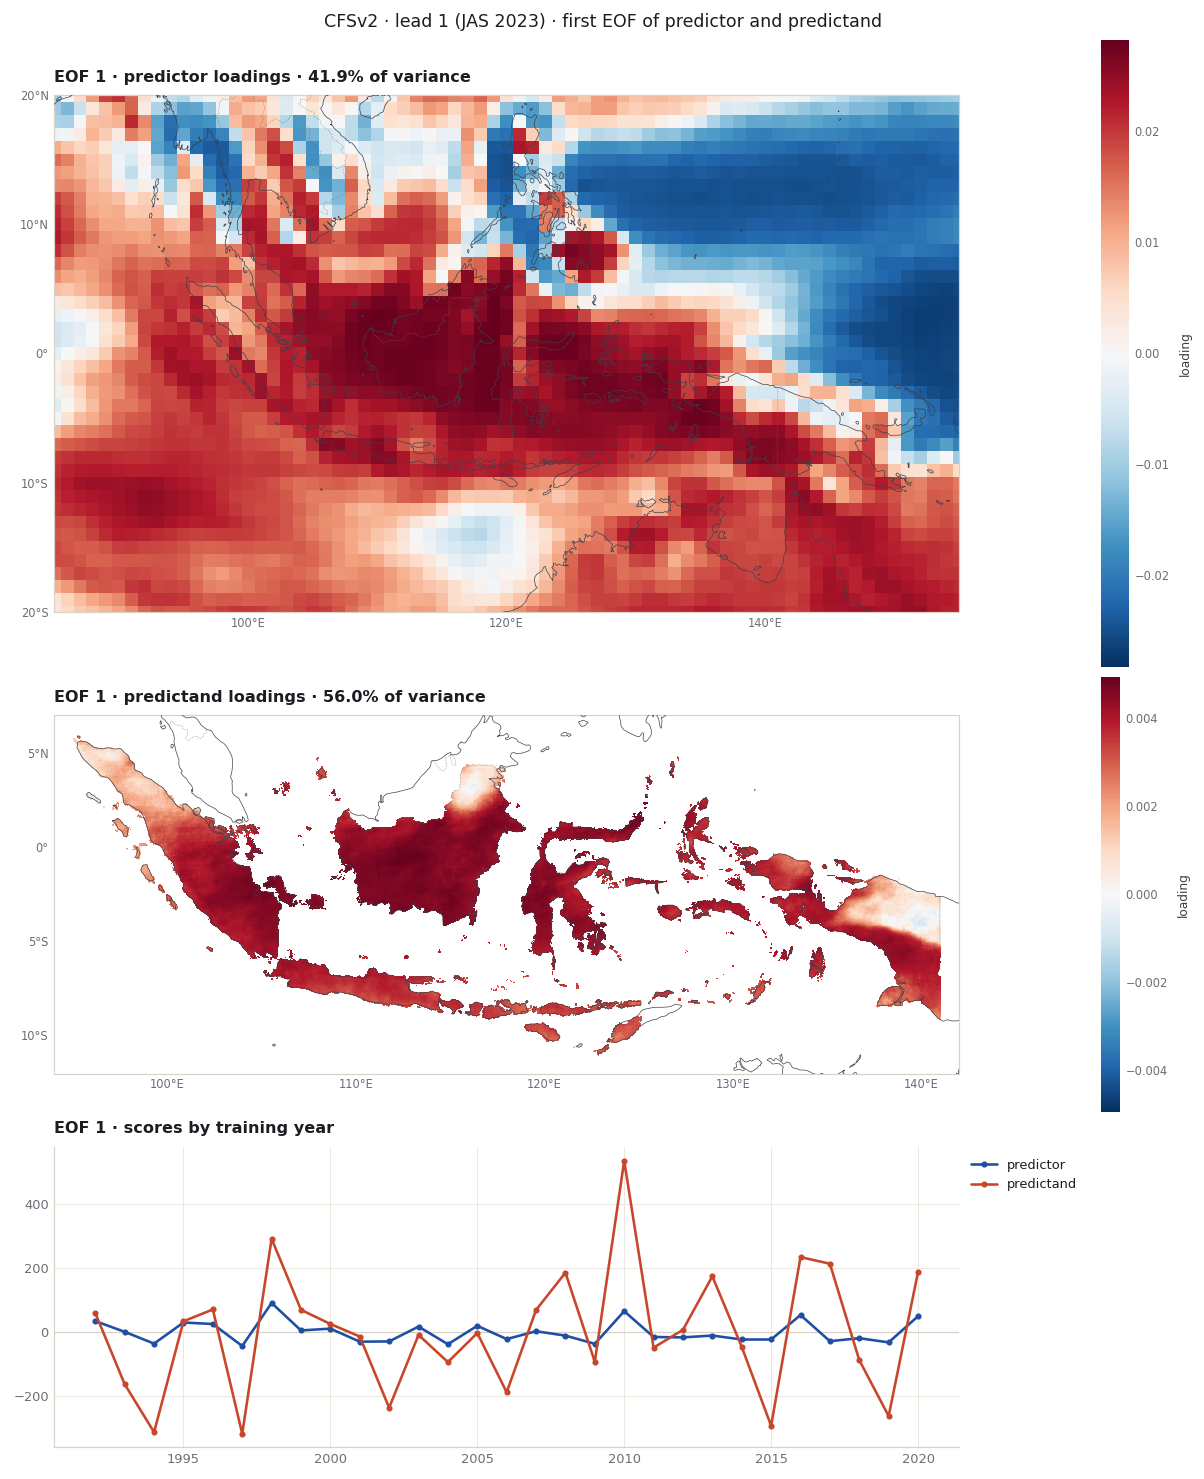

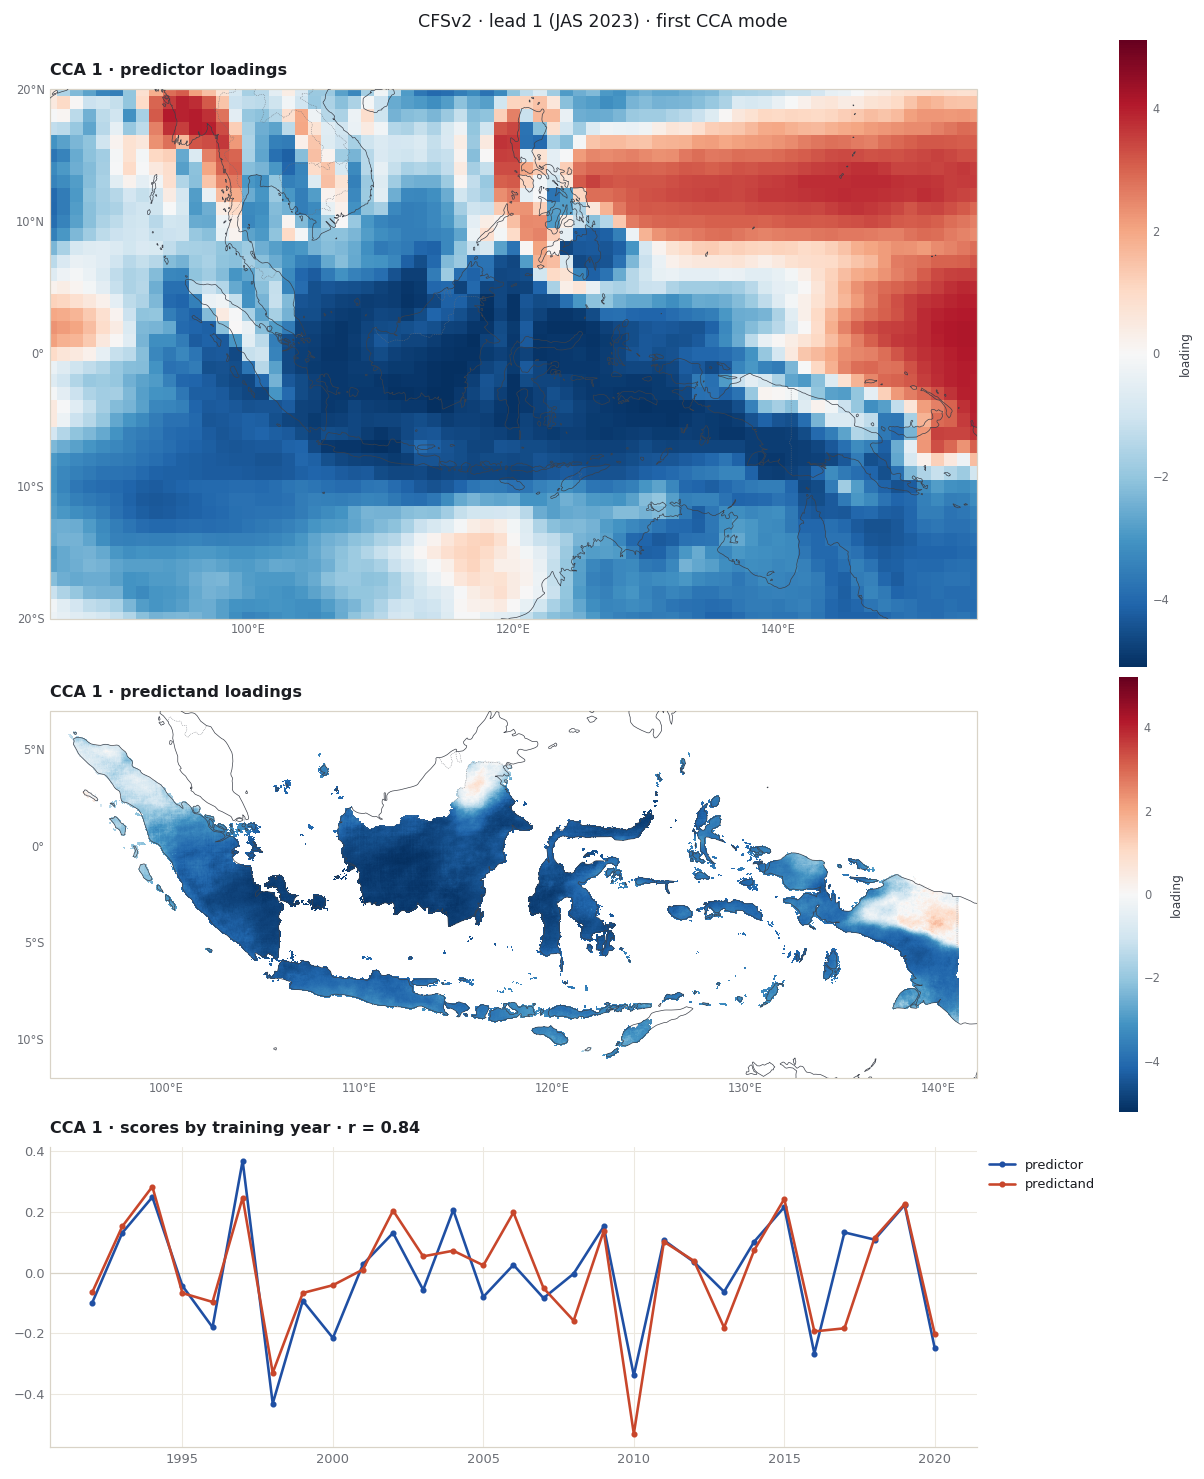

In [11]:
def as_pycpt(ds):
    # The compact file keeps the predictor grid under its own names; restore PyCPT's for plotting.
    px = ds[[v for v in ds.data_vars if v.startswith("x_")]].rename({"Yx": "Y", "Xx": "X"})
    py = ds[[v for v in ds.data_vars if v.startswith("y_")]]
    return px, py


px, py = as_pycpt(patterns[1, "CFSv2.PRCP"])
predictor_box = figures.extent_of(predictor_extent)
fig = figures.pattern_figure(px, py, "eof", 1, predictor_box, predictand_box)
fig.suptitle(f"CFSv2 · lead 1 ({label[1]}) · first EOF of predictor and predictand")
fig.savefig(assets / "eof1-cfsv2-lead1.png")
plt.show()
fig = figures.pattern_figure(px, py, "cca", 1, predictor_box, predictand_box)
fig.suptitle(f"CFSv2 · lead 1 ({label[1]}) · first CCA mode")
fig.savefig(assets / "cca1-cfsv2-lead1.png")
plt.show()

## 7. The forecasts, and what happened

Each member gives a deterministic forecast and three tercile probabilities for each
lead's target; the ensemble averages them. They are checked against the observed
totals, July-September 2023 to December 2023-February 2024, built from the same dekads.
The categories are CPT's terciles of the 1992-2020 values at each pixel (33rd and 67th
percentiles, Hazen rule).

Three scores, each area-weighted: the **hit rate** (share of area where the most
likely category was the one observed), the **RPSS** of the three probabilities against
33/34/33% odds, and the **RMSE** of the deterministic forecast. Each lead has one
outcome, so these describe 2023 and are not skill.

In [12]:
CATS = ["below normal", "near normal", "above normal"]
observed, reference_rows = {}, []
for lead in leads:
    first, last = (pd.Timestamp(v) for v in res[lead, "CFSv2.PRCP", "CCA"]["attrs"]["forecast_target"].split(" to "))
    total = pix(on_model_grid(period_total(first, last).load()))
    lower, upper = np.quantile(obs[lead], [0.33, 0.67], axis=0, method="hazen")
    category = np.where(total < lower, 0.0, np.where(total > upper, 2.0, 1.0))
    category[~np.isfinite(total)] = np.nan
    shares = {name: float(weight[category == k].sum() / weight[np.isfinite(category)].sum() * 100) for k, name in enumerate(CATS)}
    observed[lead] = dict(total=total, mean=obs[lead].mean(0), category=category, first=first, last=last, lower=lower, upper=upper)
    reference_rows.append({"lead": lead, "target": label[lead], "observed mean (mm)": area_mean(total),
                           "1992-2020 mean (mm)": area_mean(obs[lead].mean(0)),
                           **{f"observed {name} (% of area)": v for name, v in shares.items()},
                           "reference hit rate (%)": max(shares.values()), "reference category": max(shares, key=shares.get)})
targets_2023 = pd.DataFrame(reference_rows).set_index("lead")

clim_cumulative = np.array([0.33, 0.67])
forecast_rows = []
for lead in leads:
    o = observed[lead]
    outcome = np.stack([(o["category"] <= k).astype(float) for k in range(2)])
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            ok = np.isfinite(r["p"]).all(0) & np.isfinite(o["category"])
            likely = np.where(ok, r["p"].argmax(0), np.nan)
            r["likely"], r["top"] = likely, np.where(ok, r["p"].max(0), np.nan)
            w = weight * ok
            cumulative = np.cumsum(r["p"], axis=0)[:2] / 100
            rps = ((cumulative - outcome) ** 2).sum(0)
            rps_reference = ((clim_cumulative[:, None] - outcome) ** 2).sum(0)
            forecast_rows.append({"lead": lead, "target": label[lead], "model": short(name), "method": method,
                                  "hit rate (%)": float(w[likely == o["category"]].sum() / w.sum() * 100),
                                  "RPSS": float(1 - (rps[ok] * w[ok]).sum() / (rps_reference[ok] * w[ok]).sum()),
                                  "RMSE (mm)": float(np.sqrt((((r["f"] - o["total"]) ** 2)[ok] * w[ok]).sum() / w.sum())),
                                  "mean forecast (mm)": float((r["f"][ok] * w[ok]).sum() / w.sum()),
                                  "observed mean (mm)": float((o["total"][ok] * w[ok]).sum() / w.sum()),
                                  **{f"area forecast {c} (%)": float(w[likely == k].sum() / w.sum() * 100)
                                     for k, c in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(forecast_rows).set_index(["lead", "model", "method"]).sort_index()
targets_2023.round(1)

,target,observed mean (mm),1992-2020 mean (mm),observed below normal (% of area),observed near normal (% of area),observed above normal (% of area),reference hit rate (%),reference category
lead,,,,,,,,
1,JAS 2023,481.7,516.8,23.4,57.0,19.6,57.0,near normal
2,ASO 2023,442.3,570.0,64.6,26.8,8.6,64.6,below normal
3,SON 2023,502.9,673.0,74.1,23.5,2.4,74.1,below normal
4,OND 2023,625.4,798.7,76.9,17.5,5.5,76.9,below normal
5,NDJ 2023-24,790.4,848.4,50.2,28.9,20.8,50.2,below normal
6,DJF 2023-24,825.8,831.4,35.8,32.1,32.1,35.8,below normal


In [13]:
forecast_2023.xs("CCA", level="method")[["hit rate (%)", "RPSS", "RMSE (mm)"]].unstack("lead").round(2)

hit rate (%)                                     RPSS              \
lead                  1      2      3      4      5      6     1     2     3   
model                                                                          
CCSM4             43.62  66.46  74.37  77.41  55.07  50.90  0.07  0.44  0.62   
CESM1             27.34  66.85  74.54  77.43  55.45  47.26 -0.10  0.45  0.61   
CFSv2             27.74  65.55  74.43  77.71  54.72  45.71 -0.18  0.38  0.59   
CanSIPSIC3        44.15  70.30  74.31  76.96  54.67  50.87  0.09  0.37  0.59   
GEOSS2S           52.57  28.02  44.64  53.37  51.58  46.95  0.11 -0.14  0.10   
MME               34.89  69.91  74.49  77.71  55.46  49.96  0.03  0.40  0.54   
SEAS51c           35.13  70.93  73.69    NaN    NaN    NaN -0.11  0.41  0.42   
SPEAR             37.15  70.53  74.40  78.01  57.94  52.60 -0.01  0.43  0.54   

                             RMSE (mm)                                          
lead           4     5     6         1       2       3       4       5       6  
model                                                                           
CCSM4       0.60  0.26  0.17    101.12  115.95  114.09  129.85  151.86  162.84  
CESM1       0.57  0.27  0.14    148.39  120.47  103.81  126.49  146.68  165.84  
CFSv2       0.60  0.26  0.12    164.97  135.28  101.83  124.08  150.33  169.02  
CanSIPSIC3  0.50  0.25  0.14     99.63  111.12  101.82  139.96  146.89  167.17  
GEOSS2S     0.17  0.13  0.07    110.02  224.65  204.26  206.39  163.34  170.91  
MME         0.52  0.26  0.16    111.25  102.19  102.54  130.93  144.53  161.35  
SEAS51c      NaN   NaN   NaN    138.36  105.43  133.52     NaN     NaN     NaN  
SPEAR       0.47  0.27  0.19    116.29  102.60  102.11  143.16  140.48  161.78

The ensemble's most likely category at each lead (CCA members), then the observed
category, each in one column.

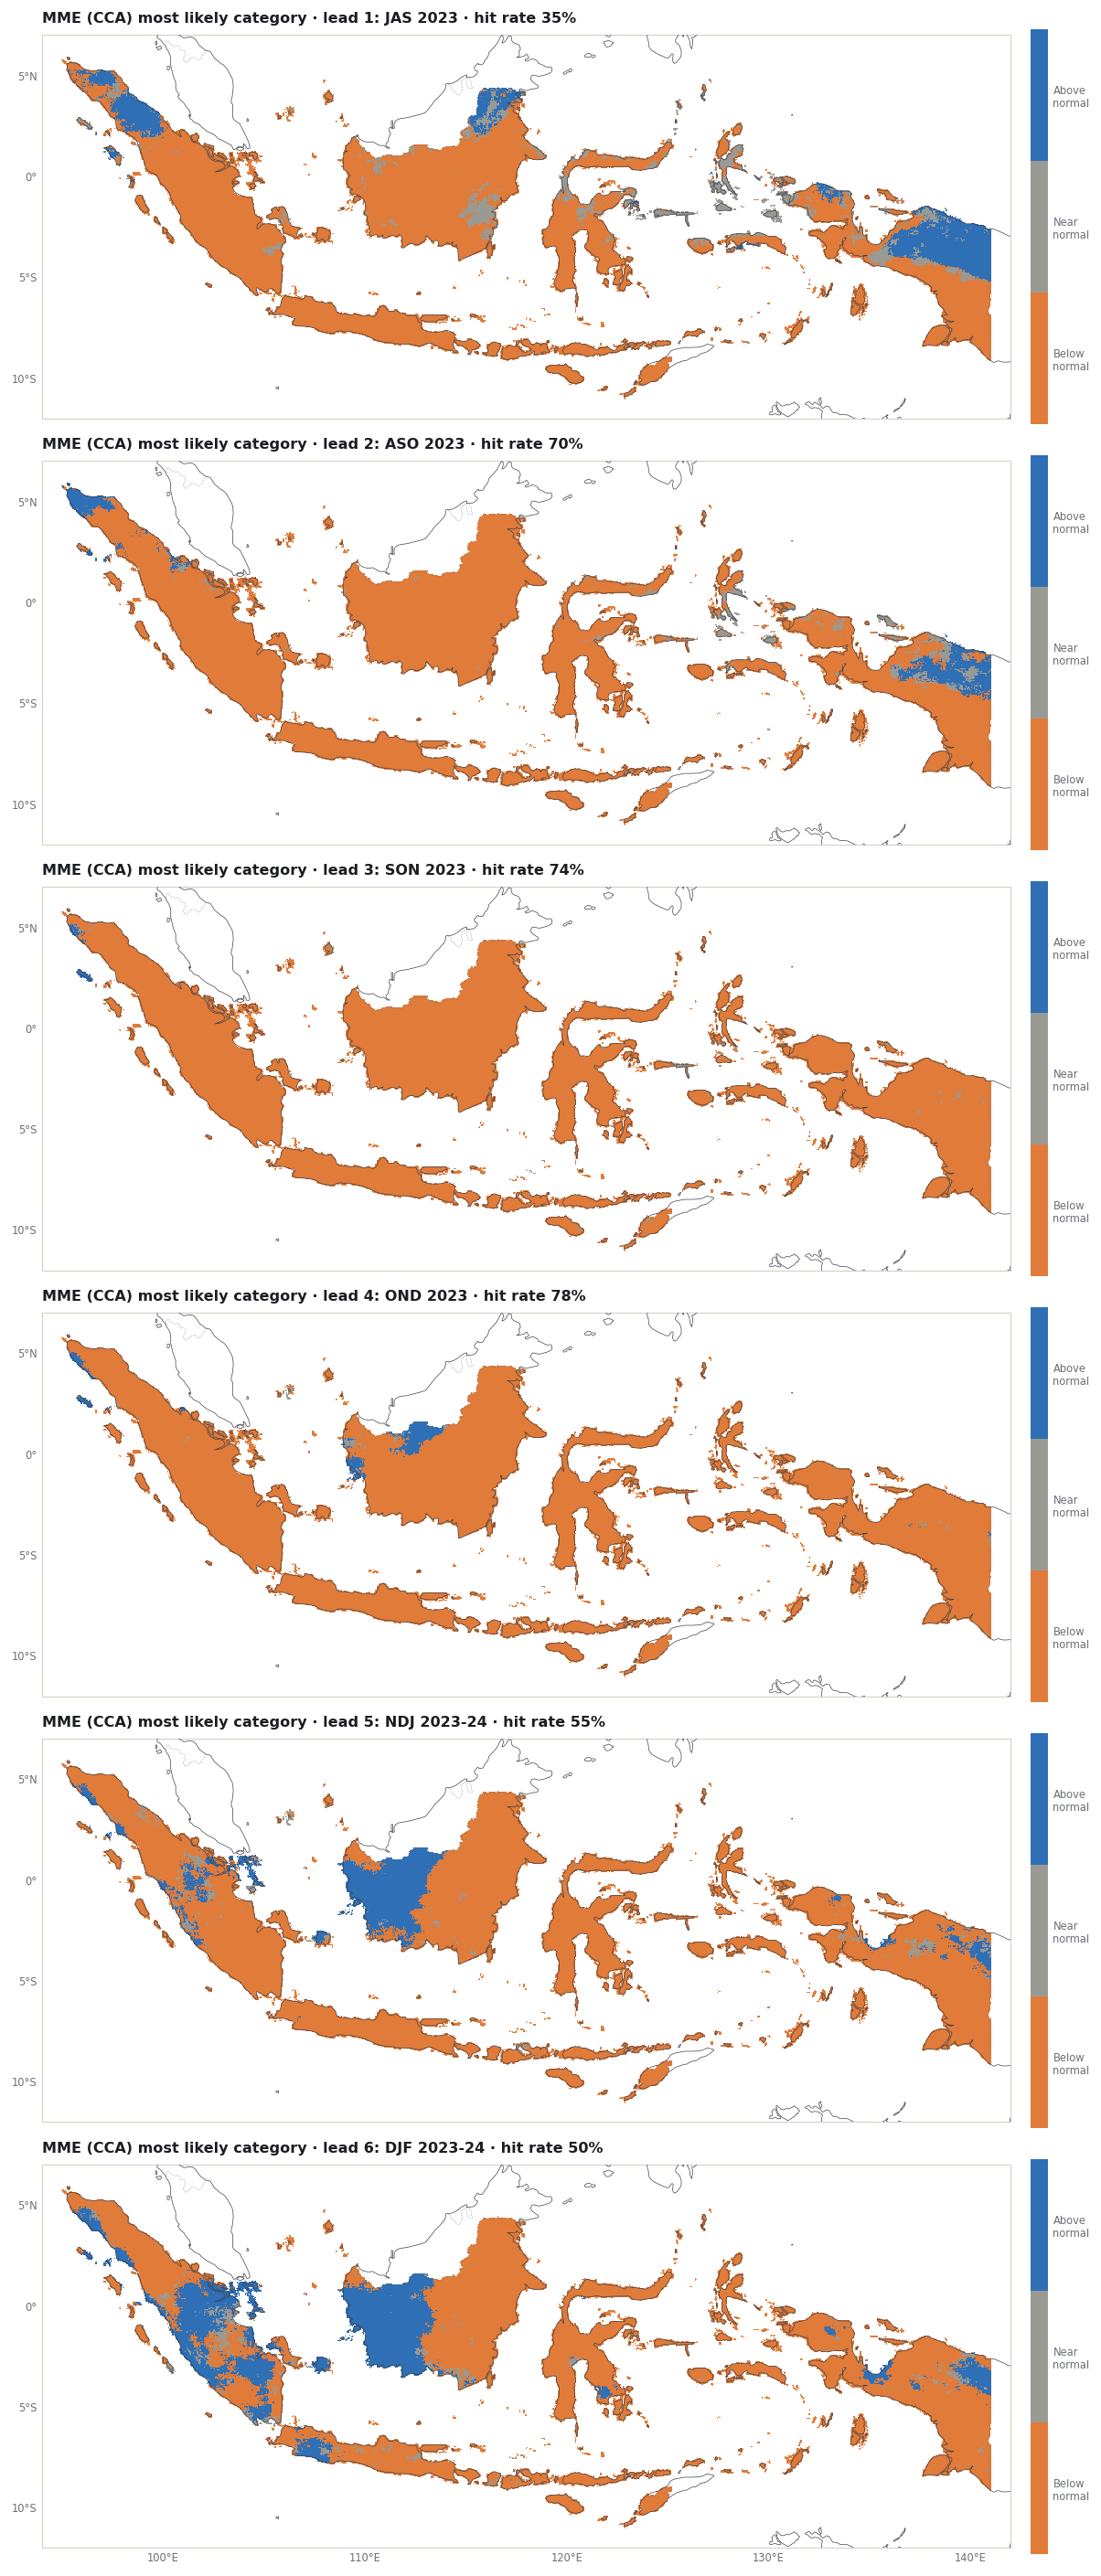

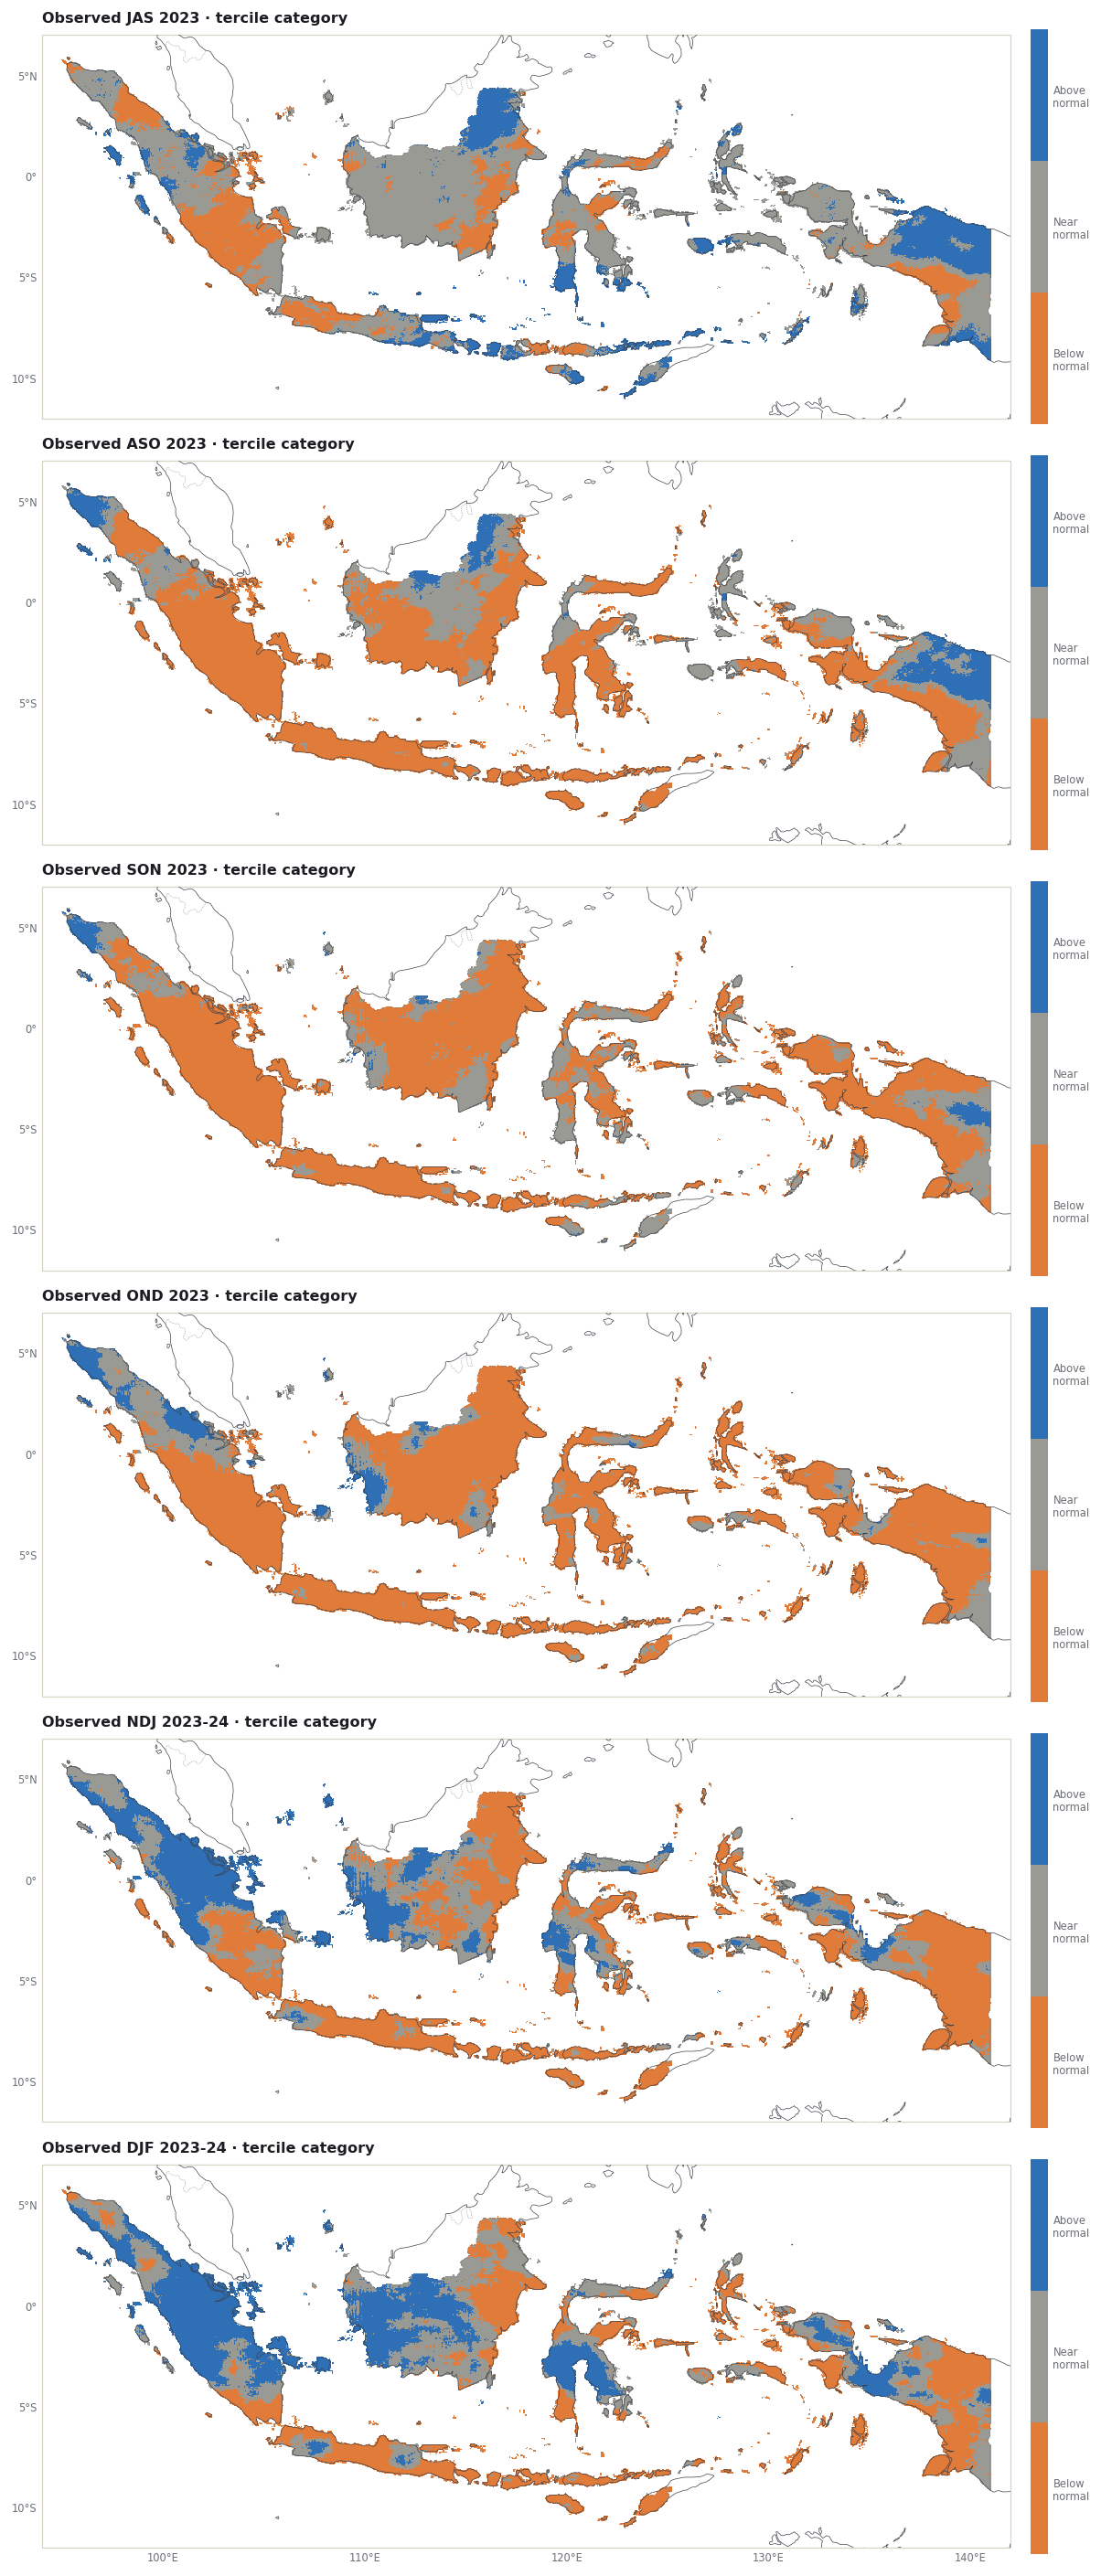

In [14]:
def category_bar(fig, image, ax):
    bar = figures.colorbar(fig, image, ax, "", ticks=[0, 1, 2])
    bar.ax.set_yticklabels(["Below\nnormal", "Near\nnormal", "Above\nnormal"])
    return bar


for kind, name in (("forecast", "mme-category-by-lead.png"), ("observed", "observed-by-lead.png")):
    fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
    for row, lead in enumerate(leads):
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
        if kind == "forecast":
            category_bar(fig, figures.category_map(ax, field(res[lead, "MME", "CCA"]["likely"])), ax)
            hit = forecast_2023.loc[(lead, "MME", "CCA"), "hit rate (%)"]
            ax.set_title(f"MME (CCA) most likely category · lead {lead}: {label[lead]} · hit rate {hit:.0f}%")
        else:
            category_bar(fig, figures.category_map(ax, field(observed[lead]["category"])), ax)
            ax.set_title(f"Observed {label[lead]} · tercile category")
    fig.savefig(assets / name)
    plt.show()

## 8. Flexible forecasts: probability of exceedance

A tercile map answers one question. The flexible forecast answers others: the
probability that the season's total exceeds a chosen amount. PyCPT's
`construct_flex_fcst` builds it from the ensemble's deterministic forecast and its
prediction error variance, as a Student's t distribution
([chapter 5](../learn/05-probabilistic-forecasts.ipynb) compares its conventions with
CPT's native ones). The fit script called it for the CCA ensemble with the
**climatological median** as the threshold, so the map reads as "chance of a wetter
than median season"; 50% everywhere would be no information.

The page's interactive view recomputes the same curve in the browser for other
thresholds from four stored fields: the forecast centre and scale, and the
climatological mean and scale. The cell below confirms that those four fields
reproduce PyCPT's own probabilities, and computes the percentile thresholds with the
rule `construct_flex_fcst` uses (`Y.quantile`, linear interpolation).

In [15]:
percentiles = [10, 20, 33, 50, 67, 80, 90]
flex_rows, quantiles, poe = [], {}, {}
for lead in leads:
    fx = res[lead, "MME", "CCA"]["flex"]
    dof = int(res[lead, "MME", "CCA"]["attrs"]["flex_degrees_of_freedom"])
    quantiles[lead] = np.quantile(obs[lead], np.array(percentiles) / 100, axis=0)             # linear rule, as Y.quantile
    rebuilt = student_t.sf(fx["threshold_median"], dof, loc=fx["forecast_mean"], scale=fx["forecast_scale"])
    poe[lead] = {p: student_t.sf(quantiles[lead][k], dof, loc=fx["forecast_mean"], scale=fx["forecast_scale"]) * 100
                 for k, p in enumerate(percentiles)}
    o = observed[lead]
    flex_rows.append({"lead": lead, "target": label[lead], "degrees of freedom": dof,
                      "rebuilt minus PyCPT, largest (pp)": float(np.nanmax(abs(rebuilt - fx["exceed_median"])) * 100),
                      "median threshold: stored minus recomputed, largest (mm)": float(np.nanmax(abs(fx["threshold_median"] - quantiles[lead][percentiles.index(50)]))),
                      "mean chance of exceeding the median (%)": area_mean(poe[lead][50]),
                      "area with chance above 50% (%)": float(weight[poe[lead][50] > 50].sum() / weight.sum() * 100),
                      "area observed above the median (%)": float(weight[o["total"] > quantiles[lead][percentiles.index(50)]].sum() / weight.sum() * 100)})
flex_table = pd.DataFrame(flex_rows).set_index("lead")
flex_table.round(3)

,target,degrees of freedom,"rebuilt minus PyCPT, largest (pp)","median threshold: stored minus recomputed, largest (mm)",mean chance of exceeding the median (%),area with chance above 50% (%),area observed above the median (%)
lead,,,,,,,
1,JAS 2023,29,0.0,0.0,34.828,13.051,42.223
2,ASO 2023,29,0.0,0.0,29.464,5.560,15.670
3,SON 2023,29,0.0,0.0,21.907,0.441,6.562
4,OND 2023,29,0.0,0.0,23.699,2.358,11.451
5,NDJ 2023-24,29,0.0,0.0,33.443,13.035,32.771
6,DJF 2023-24,29,0.0,0.0,38.492,23.443,46.456


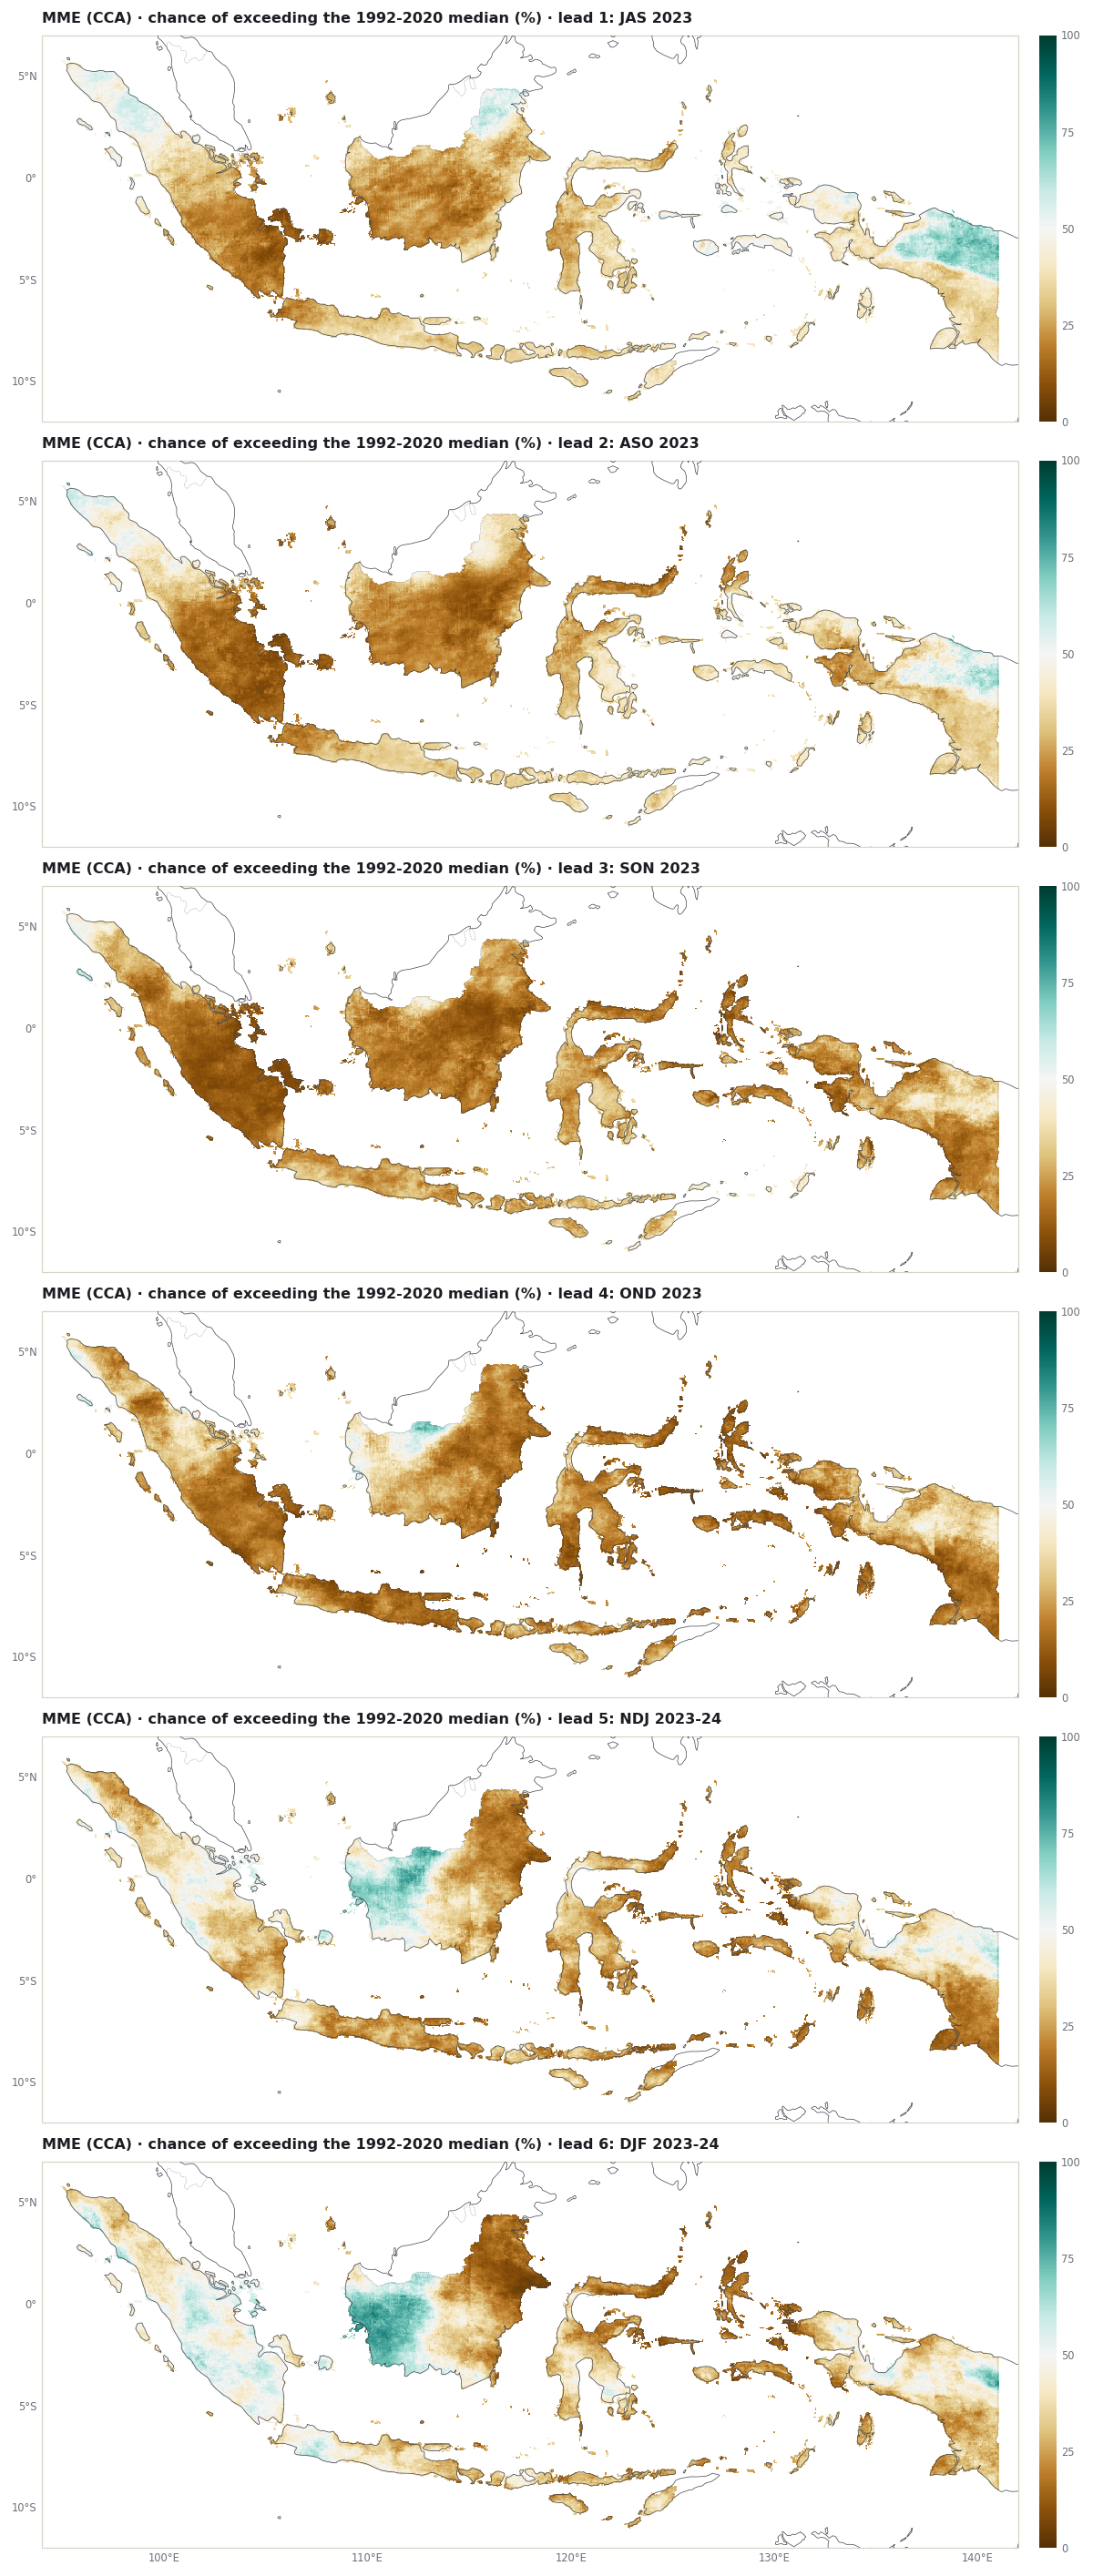

In [16]:
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, field(poe[lead][50]), cmap="BrBG", vmin=0, vmax=100)
    ax.set_title(f"MME (CCA) · chance of exceeding the 1992-2020 median (%) · lead {lead}: {label[lead]}")
    figures.colorbar(fig, image, ax, "", ticks=[0, 25, 50, 75, 100])
fig.savefig(assets / "poe-median-by-lead.png")
plt.show()

At one place the whole curve can be read. The pixel nearest Jakarta, lead 1: the
forecast distribution against the climatology, as a probability of exceedance and as
a density. The climatology is drawn two ways, as PyCPT does: the 29 observed totals
(steps) and a normal distribution fitted to them.

One detail from PyCPT 2.10.4's `plot_mme_flex_forecast_v2`: its exceedance panel draws
the fitted climatology with the *forecast* scale, while its density panel uses the
climatological scale. Here both panels use the climatological scale.

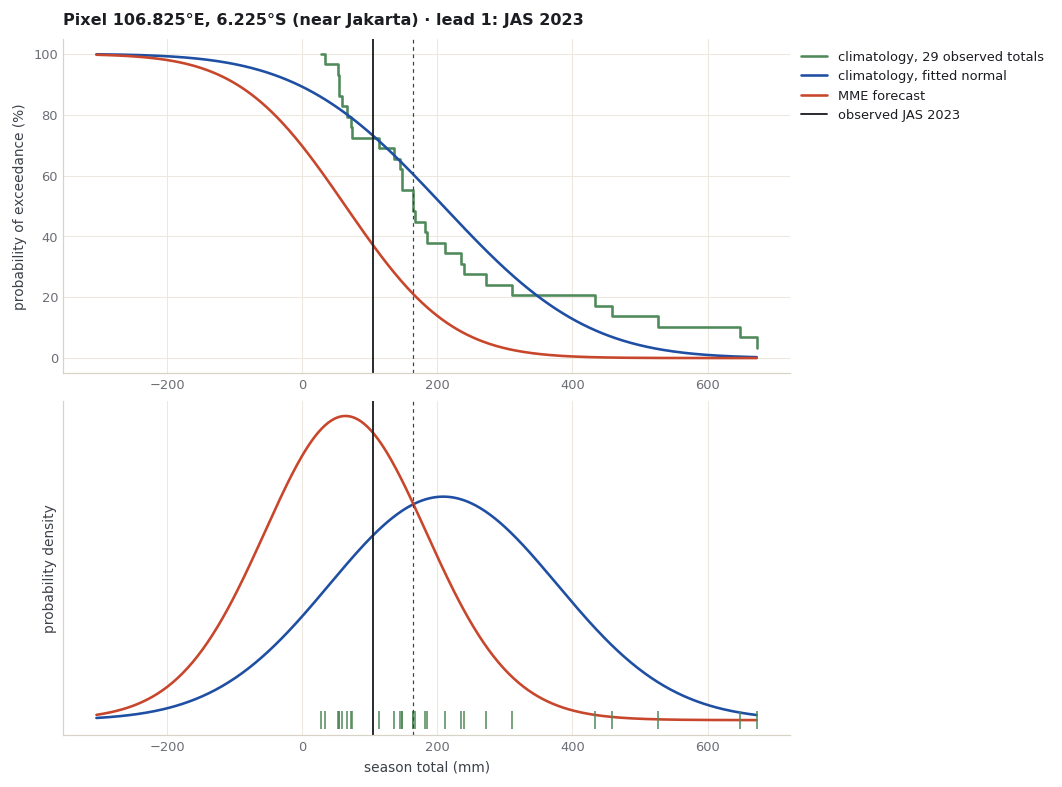

{'exceed_median': 0.2, 'forecast_scale': 122.9, 'climatology_scale': 168.7, 'forecast_mean': 64.0, 'climatology_mean': 208.8, 'threshold_median': 163.3} | observed: 105.0 | chance of exceeding the median: 21.3 %


In [17]:
point = int(np.argmin((pixel_lon - 106.85) ** 2 + (pixel_lat + 6.20) ** 2))
lead = 1
fx = {k: float(v[point]) for k, v in res[lead, "MME", "CCA"]["flex"].items()}
dof = int(res[lead, "MME", "CCA"]["attrs"]["flex_degrees_of_freedom"])
history = np.sort(obs[lead][:, point])
x = np.linspace(min(history.min(), fx["forecast_mean"] - 3 * fx["forecast_scale"]), max(history.max(), fx["forecast_mean"] + 3 * fx["forecast_scale"]), 400)
fig, grid = figures.stacked([3.0, 3.0], width=figures.MAP_WIDTH)
ax = fig.add_subplot(grid[0, 0])
ax.step(history, [(history >= v).mean() * 100 for v in history], where="post", color=figures.GREEN, label="climatology, 29 observed totals")
ax.plot(x, norm.sf(x, fx["climatology_mean"], fx["climatology_scale"]) * 100, color=figures.ACCENT, label="climatology, fitted normal")
ax.plot(x, student_t.sf(x, dof, fx["forecast_mean"], fx["forecast_scale"]) * 100, color=figures.MARK, label="MME forecast")
ax.axvline(fx["threshold_median"], color=figures.INK_2, linewidth=.8, linestyle=(0, (3, 3)))
ax.axvline(observed[lead]["total"][point], color=figures.INK, linewidth=1.2, label=f"observed {label[lead]}")
ax.set(ylabel="probability of exceedance (%)", title=f"Pixel {pixel_lon[point]:.3f}°E, {abs(pixel_lat[point]):.3f}°S (near Jakarta) · lead 1: {label[1]}")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax = fig.add_subplot(grid[1, 0])
ax.plot(x, norm.pdf(x, fx["climatology_mean"], fx["climatology_scale"]), color=figures.ACCENT)
ax.plot(x, student_t.pdf(x, dof, fx["forecast_mean"], fx["forecast_scale"]), color=figures.MARK)
ax.plot(history, np.zeros_like(history), "|", color=figures.GREEN, markersize=12)
ax.axvline(fx["threshold_median"], color=figures.INK_2, linewidth=.8, linestyle=(0, (3, 3)))
ax.axvline(observed[lead]["total"][point], color=figures.INK, linewidth=1.2)
ax.set(xlabel="season total (mm)", ylabel="probability density", yticks=[])
fig.savefig(assets / "flex-point-lead1.png")
plt.show()
print({k: round(v, 1) for k, v in fx.items()}, "| observed:", round(float(observed[lead]["total"][point]), 1),
      "| chance of exceeding the median:", round(float(poe[lead][50][point]), 1), "%")

## 9. Save the results

Tables as CSV, the maps as one NetCDF file, and the browser files the story page
reads: a manifest, a shared pixel list and one small gzip-compressed binary file per
map, loaded only when a view needs it.

In [18]:
data_dir.mkdir(parents=True, exist_ok=True)
skill_table.round(4).to_csv(data_dir / "skill-by-lead.csv")
gain.round(4).to_csv(data_dir / "mme-against-members.csv")
forecast_2023.round(4).to_csv(data_dir / f"issued-{issue:%Y-%m}-forecasts.csv")
targets_2023.round(4).to_csv(data_dir / f"issued-{issue:%Y-%m}-observed.csv")
mode_table.round(4).to_csv(data_dir / "eof-cca-modes.csv")
flex_table.round(4).to_csv(data_dir / "flexible-forecast.csv")
summary = {"issued": issue.date().isoformat(), "leads_months": leads,
           "targets": {lead: {"pycpt_target": targets[lead], "label": label[lead], "first_day": f"{observed[lead]['first']:%Y-%m-%d}",
                               "last_day": f"{observed[lead]['last']:%Y-%m-%d}", "members": [short(m) for m in members[lead]]} for lead in leads},
           "training_target_years": [training_years[0], training_years[-1]], "pixels": n, "grid": "native 0.05 degree",
           "settings": {k: str(v) for k, v in cpt_args.items()},
           "checks": {k: float(v) for k, v in gaps.items()},
           "no_model_cross_validated_pearson": {lead: round(v, 4) for lead, v in no_model_pearson.items()},
           "fit_seconds": {f"{r['lead']}-{short(r['model'])}-{r['method']}": r["seconds"] for r in fit_records if "model" in r}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    maps[f"observed_lead{lead}"] = field(observed[lead]["total"])
    maps[f"observed_category_lead{lead}"] = field(observed[lead]["category"])
    maps[f"poe_median_mme_cca_lead{lead}"] = field(poe[lead][50])
    for method in ("CCA", "PCR"):
        r = res[lead, "MME", method]
        maps[f"mme_{method.lower()}_pearson_lead{lead}"] = field(r["pearson"])
        maps[f"mme_{method.lower()}_cv_rpss_lead{lead}"] = field(r["rpss"])
        maps[f"mme_{method.lower()}_forecast_lead{lead}"] = field(r["f"])
        maps[f"mme_{method.lower()}_most_likely_lead{lead}"] = field(r["likely"])
save_netcdf(maps, data_dir / "seasonal-mme-2023-maps.nc", overwrite=True,
            metadata={"note": "Multi-model ensemble issued 1 June 2023, leads 1-6 months (JAS 2023 to DJF 2023-24), training 1992-2020; categories 0 below, 1 near, 2 above normal"})
for f in sorted(data_dir.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/seasonal-mme-2023/availability.json  (32 kB)
docs/data/seasonal-mme-2023/eof-cca-modes.csv  (3 kB)
docs/data/seasonal-mme-2023/flexible-forecast.csv  (1 kB)
docs/data/seasonal-mme-2023/issued-2023-06-forecasts.csv  (8 kB)
docs/data/seasonal-mme-2023/issued-2023-06-observed.csv  (1 kB)
docs/data/seasonal-mme-2023/issued-2023-11-forecasts.csv  (8 kB)
docs/data/seasonal-mme-2023/issued-2023-11-observed.csv  (1 kB)
docs/data/seasonal-mme-2023/mme-against-members.csv  (1 kB)
docs/data/seasonal-mme-2023/seasonal-mme-2023-maps.nc  (18309 kB)
docs/data/seasonal-mme-2023/skill-by-lead.csv  (5 kB)
docs/data/seasonal-mme-2023/summary.json  (5 kB)


In [19]:
def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


def encode(values, kind, scale, offset=0.0):
    v = np.round((np.asarray(values, dtype="float64") - offset) * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    if kind == "i8":
        return np.where(np.isfinite(v), np.clip(v, -127, 127), -128).astype("i1").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


field_dir = assets / "fields"
field_dir.mkdir(parents=True, exist_ok=True)
for old in field_dir.glob("*"):
    old.unlink()
layout = {"skill": [["value", "u8", 100, -1]],
          "obs": [["total", "u16", 1], ["mean", "u16", 1], ["category", "u8", 1]],
          "fc": [["total", "u16", 1], ["below", "u8", 2], ["above", "u8", 2]],
          "flex": [["mu", "u16", 10], ["scale", "u16", 10], ["cmu", "u16", 10], ["cscale", "u16", 10]],
          "quant": [[f"q{p}", "u16", 1] for p in percentiles],
          "yeof": [[f"m{k}", "i8", 127] for k in (1, 2, 3)], "ycca": [[f"m{k}", "i8", 127] for k in (1, 2)]}


def write(name, kind, parts):
    spec = layout[kind]
    assert len(spec) == len(parts)
    blob = b"".join(encode(v, s[1], s[2], s[3] if len(s) > 3 else 0.0) for v, s in zip(parts, spec))
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(blob, 9, mtime=0))


def unit(a):
    return a / np.nanmax(abs(a))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
lead_key = {lead: f"lead{lead}" for lead in leads}
target_info, issue_targets = [], []
for lead in leads:
    o, key = observed[lead], lead_key[lead]
    days = (o["last"] - o["first"]).days + 1
    target_info.append({"lead": lead, "label": label[lead], "pycpt": targets[lead], "start": f"{o['first']:%Y-%m-%d}",
                        "end": f"{o['last'] + pd.Timedelta(days=1):%Y-%m-%d}"})
    issue_targets.append({"lead": key, "start": f"{o['first']:%Y-%m-%d}", "days": int(days)})
    write(f"obs-{key}", "obs", [o["total"], o["mean"], o["category"]])
    fx = res[lead, "MME", "CCA"]["flex"]
    write(f"flex-{key}", "flex", [fx["forecast_mean"], fx["forecast_scale"], fx["climatology_mean"], fx["climatology_scale"]])
    write(f"quant-{key}", "quant", list(quantiles[lead]))
    y_eof = pix(patterns[lead, "CFSv2.PRCP"].y_eof_loadings)
    write(f"yeof-{key}", "yeof", [unit(y_eof[k]) for k in range(3)])
    lead_patterns = {"years": training_years, "models": {}}
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            write(f"skill-{short(name)}-{method}-pearson-{key}", "skill", [r["pearson"]])
            write(f"skill-{short(name)}-{method}-rpss-{key}", "skill", [np.clip(r["rpss"], -1, 1)])
            write(f"fc-{short(name)}-{method}-{key}", "fc", [r["f"], r["p"][0], r["p"][2]])
        write(f"skill-{short(name)}-raw-pearson-{key}", "skill", [res[lead, name, "raw"]["pearson"]])
        if name == "MME":
            continue
        ds = patterns[lead, name]
        y_cca = pix(ds.y_cca_loadings)
        write(f"ycca-{short(name)}-{key}", "ycca", [unit(y_cca[k]) for k in range(2)])
        clean = lambda a: [None if not np.isfinite(v) else round(float(v), 3) for v in np.asarray(a).ravel()]
        lead_patterns["models"][short(name)] = {
            "lat": [float(v) for v in ds["Yx"].values], "lon": [float(v) for v in ds["Xx"].values],
            "xEof": [[None if not np.isfinite(v) else round(float(v), 2) for v in unit(ds.x_eof_loadings.sel(Mode=k).transpose("Yx", "Xx").values).ravel()] for k in (1, 2, 3)],
            "xCca": [[None if not np.isfinite(v) else round(float(v), 2) for v in unit(ds.x_cca_loadings.sel(Mode=k).transpose("Yx", "Xx").values).ravel()] for k in (1, 2)],
            "xEofScores": [clean(ds.x_eof_scores.sel(Mode=k)) for k in (1, 2, 3)], "yEofScores": [clean(ds.y_eof_scores.sel(Mode=k)) for k in (1, 2, 3)],
            "xCcaScores": [clean(ds.x_cca_scores.sel(Mode=k)) for k in (1, 2)], "yCcaScores": [clean(ds.y_cca_scores.sel(Mode=k)) for k in (1, 2)],
            "xVariance": clean(ds.x_explained_variance.sel(Mode=[1, 2, 3])), "yVariance": clean(ds.y_explained_variance.sel(Mode=[1, 2, 3])),
            "canonical": [round(float(mode_table.loc[(lead, short(name)), f"canonical correlation {k}"]), 3) for k in (1, 2)]}
    (assets / f"patterns-{key}.json").write_text(json.dumps(lead_patterns, separators=(",", ":"), allow_nan=False) + "\n")

values = np.concatenate([observed[lead]["total"] for lead in leads] + [res[lead, "MME", "CCA"]["f"] for lead in leads])
top = float(np.ceil(np.nanpercentile(values, 99) / 100) * 100)
manifest = {
    "grid": {"west": round(float(grid_X.min()) - .025, 3), "north": round(float(grid_Y.max()) + .025, 3), "step": 0.05,
             "nx": int(grid_mask.sizes["X"]), "ny": int(grid_mask.sizes["Y"]), "pixels": n},
    "kind": "season", "issue": {"date": issue.date().isoformat(), "label": f"{issue.day} {issue:%b %Y}"},
    "issues": [{"issued": issue.date().isoformat(), "label": f"{issue.day} {issue:%b %Y}", "targets": issue_targets}],
    "leads": leads, "leadKeys": [lead_key[lead] for lead in leads], "methods": ["CCA", "PCR"], "unit": "mm",
    "training": "1992-2020", "sample": "the 29 training years, 1992-2020", "cellText": f"Indonesia's {n:,} pixels at 0.05°",
    "leadNames": [f"Lead {lead} · {label[lead]}" for lead in leads], "targets": target_info,
    "models": [short(m) for m in order] + ["MME"], "members": {lead_key[lead]: [short(m) for m in members[lead]] for lead in leads},
    "modelColors": {**model_colours, "MME": figures.INK},
    "predictorBox": predictor_extent, "percentiles": percentiles,
    "flexDof": {lead_key[lead]: int(res[lead, "MME", "CCA"]["attrs"]["flex_degrees_of_freedom"]) for lead in leads},
    "layout": layout, "rainMax": top, "rainLegend": "mm in the season",
    "skillTable": records(skill_table.reset_index().round(4)),
    "gain": records(gain.reset_index().round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "references": records(targets_2023.reset_index().round(3)),
}
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(q.stat().st_size for q in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"pattern files {sum(q.stat().st_size for q in assets.glob('patterns-*.json')) / 1e6:.1f} MB; colour scale up to {top:.0f} mm")

69,640 pixels; 378 field files, 40.7 MB in total (largest 686 kB); pattern files 3.2 MB; colour scale up to 1400 mm
